PRCP-1006: Home Loan Default Prediction

1. Project Introduction

1.1 Objective

The objective of this project is to perform a complete data analysis and develop a predictive model to identify factors and customer segments eligible for taking a loan.

1.2 Domain

Banking

1.3 Project Tasks

1.Prepare a complete data analysis report on the given dataset.

2.Create a predictive model to identify factors and customer segments eligible for taking a loan.

3.Compare the performance of multiple models and recommend the best model for production.

4.Document the challenges faced, techniques used, and reasons for selecting those techniques.

2. Importing the Required Libraries

2.1 Objective

Import the Python libraries required for data manipulation, numerical calculations, data visualization, and machine learning.

2.2 Import the libraries

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

2.3 Verify the imports

In [2]:
print("All required libraries imported successfully.")

All required libraries imported successfully.


3. Loading the Dataset

3.1 Objective

Load the dataset files into Python using Pandas and check whether the files are accessible.

3.2 Check the Dataset Folder

application_train.csv



bureau.csv



bureau_balance.csv



POS_CASH_balance.csv



credit_card_balance.csv



previous_application.csv



installments_payments.csv

3.3 Import the Dataset

In [3]:
import os
# Display files in the current working directory
print(os.listdir())

['-1.14-windows.xml', '.anaconda', '.antigravity-ide', '.bash_history', '.cache', '.codex', '.conda', '.config', '.continuum', '.copilot', '.gemini', '.gitconfig', '.ipynb_checkpoints', '.ipython', '.jupyter', '.keras', '.lesshst', '.local', '.matplotlib', '.vscode', '.vscode-shared', '3D Objects', 'ADS', 'ADS.b0b69832-cd08-4bb3-b4ec-e04e25277230', 'anaconda3', 'anaconda_projects', 'AppData', 'Application Data', 'Contacts', 'Cookies', 'Desktop', 'Documents', 'Downloads', 'Favorites', 'HomeLoanDef.ipynb', 'Links', 'Local Settings', 'Machine Learning Associate_Numpy', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{e11ac56d-4c10-11f1-a9ac-d8f3bcd848f9}.TM.blf', 'NTUSER.DAT{e11ac56d-4c10-11f1-a9ac-d8f3bcd848f9}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{e11ac56d-4c10-11f1-a9ac-d8f3bcd848f9}.TMContainer00000000000000000002.regtrans-ms', 'ntuser.ini', 'OneDrive', 'Pictures', 'PrintHood', 'Python_class', 'Recent', 'RiceLeafPr

3.4 Load the Main Dataset

In [1]:
import pandas as pd
import os

data_path = r"E:\HomeLoanDef\Data"

application_train = pd.read_csv(
    os.path.join(data_path, "application_train.csv")
)

print("Dataset loaded successfully.")

Dataset loaded successfully.


3.5 Verify the Dataset

In [5]:
application_train.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:
application_train.shape

(307511, 122)

4. Understanding the Dataset

4.1 Objective

Understand the structure of the main dataset, including the number of records, column names, data types, and overall information.

4.2 Check the Number of Rows and Columns

In [7]:
print("Number of Rows:", application_train.shape[0])
print("Number of Columns:", application_train.shape[1])

Number of Rows: 307511
Number of Columns: 122


4.3 Display All Column Names

In [8]:
application_train.columns

Index(['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER',
       'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL',
       'AMT_CREDIT', 'AMT_ANNUITY',
       ...
       'FLAG_DOCUMENT_18', 'FLAG_DOCUMENT_19', 'FLAG_DOCUMENT_20',
       'FLAG_DOCUMENT_21', 'AMT_REQ_CREDIT_BUREAU_HOUR',
       'AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_WEEK',
       'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT',
       'AMT_REQ_CREDIT_BUREAU_YEAR'],
      dtype='object', length=122)

4.4 Check Dataset Information

In [9]:
application_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB


4.5 Display the First Five Records

In [10]:
application_train.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


4.6 Display the Last Five Records

In [11]:
application_train.tail()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
307506,456251,0,Cash loans,M,N,N,0,157500.0,254700.0,27558.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307507,456252,0,Cash loans,F,N,Y,0,72000.0,269550.0,12001.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307508,456253,0,Cash loans,F,N,Y,0,153000.0,677664.0,29979.0,...,0,0,0,0,1.0,0.0,0.0,1.0,0.0,1.0
307509,456254,1,Cash loans,F,N,Y,0,171000.0,370107.0,20205.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
307510,456255,0,Cash loans,F,N,N,0,157500.0,675000.0,49117.5,...,0,0,0,0,0.0,0.0,0.0,2.0,0.0,1.0


4.7 Generate a Statistical Summary

In [12]:
application_train.describe()

,SK_ID_CURR,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,307511.000000,307511.000000,307511.000000,3.075110e+05,3.075110e+05,307499.000000,3.072330e+05,307511.000000,307511.000000,307511.000000,...,307511.000000,307511.000000,307511.000000,307511.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000
mean,278180.518577,0.080729,0.417052,1.687979e+05,5.990260e+05,27108.573909,5.383962e+05,0.020868,-16036.995067,63815.045904,...,0.008130,0.000595,0.000507,0.000335,0.006402,0.007000,0.034362,0.267395,0.265474,1.899974
std,102790.175348,0.272419,0.722121,2.371231e+05,4.024908e+05,14493.737315,3.694465e+05,0.013831,4363.988632,141275.766519,...,0.089798,0.024387,0.022518,0.018299,0.083849,0.110757,0.204685,0.916002,0.794056,1.869295
min,100002.000000,0.000000,0.000000,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04,0.000290,-25229.000000,-17912.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,189145.500000,0.000000,0.000000,1.125000e+05,2.700000e+05,16524.000000,2.385000e+05,0.010006,-19682.000000,-2760.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,278202.000000,0.000000,0.000000,1.471500e+05,5.135310e+05,24903.000000,4.500000e+05,0.018850,-15750.000000,-1213.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,367142.500000,0.000000,1.000000,2.025000e+05,8.086500e+05,34596.000000,6.795000e+05,0.028663,-12413.000000,-289.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,456255.000000,1.000000,19.000000,1.170000e+08,4.050000e+06,258025.500000,4.050000e+06,0.072508,-7489.000000,365243.000000,...,1.000000,1.000000,1.000000,1.000000,4.000000,9.000000,8.000000,27.000000,261.000000,25.000000


5. Data Quality Checking

5.1 Objective

Check the dataset for missing values, duplicate records, and data type issues before performing data analysis.

5.2 Check Missing Values

In [13]:
# Check missing values in each column
application_train.isnull().sum()

SK_ID_CURR                        0
TARGET                            0
NAME_CONTRACT_TYPE                0
CODE_GENDER                       0
FLAG_OWN_CAR                      0
                              ...  
AMT_REQ_CREDIT_BUREAU_DAY     41519
AMT_REQ_CREDIT_BUREAU_WEEK    41519
AMT_REQ_CREDIT_BUREAU_MON     41519
AMT_REQ_CREDIT_BUREAU_QRT     41519
AMT_REQ_CREDIT_BUREAU_YEAR    41519
Length: 122, dtype: int64

5.3 Calculate the Percentage of Missing Values

In [14]:
# Calculate missing value percentage
missing_percentage = (
    application_train.isnull().sum() / len(application_train)
) * 100

missing_percentage = missing_percentage.sort_values(ascending=False)

missing_percentage[missing_percentage > 0]

COMMONAREA_MEDI             69.872297
COMMONAREA_AVG              69.872297
COMMONAREA_MODE             69.872297
NONLIVINGAPARTMENTS_MODE    69.432963
NONLIVINGAPARTMENTS_AVG     69.432963
                              ...    
EXT_SOURCE_2                 0.214626
AMT_GOODS_PRICE              0.090403
AMT_ANNUITY                  0.003902
CNT_FAM_MEMBERS              0.000650
DAYS_LAST_PHONE_CHANGE       0.000325
Length: 67, dtype: float64

5.4 Check Duplicate Records

In [15]:
# Count duplicate rows
print("Number of Duplicate Rows:", application_train.duplicated().sum())

Number of Duplicate Rows: 0


5.5 Check Data Types

In [16]:
# Display the data type of each column
application_train.dtypes

SK_ID_CURR                      int64
TARGET                          int64
NAME_CONTRACT_TYPE             object
CODE_GENDER                    object
FLAG_OWN_CAR                   object
                               ...   
AMT_REQ_CREDIT_BUREAU_DAY     float64
AMT_REQ_CREDIT_BUREAU_WEEK    float64
AMT_REQ_CREDIT_BUREAU_MON     float64
AMT_REQ_CREDIT_BUREAU_QRT     float64
AMT_REQ_CREDIT_BUREAU_YEAR    float64
Length: 122, dtype: object

5.6 Generate a Data Quality Summary

In [17]:
# Summarize dataset quality
print("Total Rows:", application_train.shape[0])
print("Total Columns:", application_train.shape[1])
print("Total Missing Values:", application_train.isnull().sum().sum())
print("Total Duplicate Rows:", application_train.duplicated().sum())

Total Rows: 307511
Total Columns: 122
Total Missing Values: 9152465
Total Duplicate Rows: 0


6. Target Variable Analysis

6.1 Objective

Analyze the target variable TARGET to understand the distribution of customers who defaulted and those who did not default.

- TARGET = 1 — Defaulter
- TARGET = 0 — Not Defaulter

6.2 Check the Target Variable

In [18]:
# Display the unique values in the target column
application_train['TARGET'].unique()

array([1, 0])

6.3 Count the Defaulters and Non-Defaulters

In [19]:
# Count target classes
target_counts = application_train['TARGET'].value_counts().sort_index()
print(target_counts)

TARGET
0    282686
1     24825
Name: count, dtype: int64


6.4 Calculate the Percentage Distribution

In [20]:
# Calculate percentage distribution
target_percentage = (
    application_train['TARGET'].value_counts(normalize=True).sort_index() * 100
)

print(target_percentage)

TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64


6.5 Visualize the Target Distribution

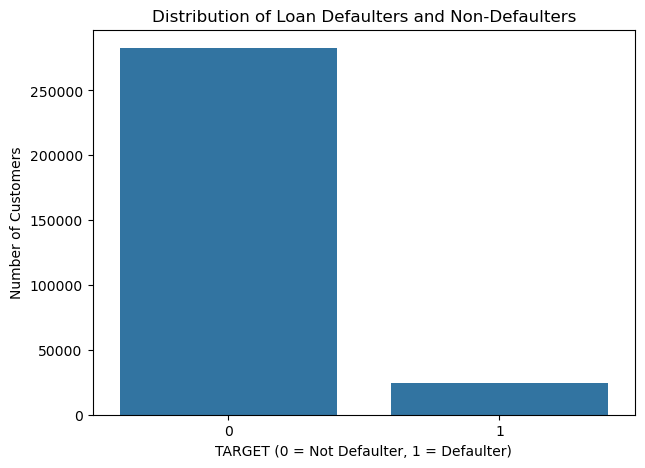

In [21]:
# Plot target class distribution
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=application_train, x='TARGET')

plt.title('Distribution of Loan Defaulters and Non-Defaulters')
plt.xlabel('TARGET (0 = Not Defaulter, 1 = Defaulter)')
plt.ylabel('Number of Customers')

plt.show()

### 6.6 Observation

The target variable represents whether a customer defaulted on a loan.
The distribution of defaulters and non-defaulters was examined using
frequency counts, percentage distribution, and a count plot.

The class distribution will help determine whether the dataset is
imbalanced and guide the selection of appropriate evaluation metrics.

7. Univariate Data Analysis

7.1 Objective

Analyze individual features in the application_train dataset to understand their distributions and identify patterns in the data.

7.2 Analyze Numerical Features

In [22]:
# Select numerical columns
numerical_columns = application_train.select_dtypes(
    include=['int64', 'float64']
).columns

print("Number of Numerical Columns:", len(numerical_columns))
print(numerical_columns.tolist())

Number of Numerical Columns: 106
['SK_ID_CURR', 'TARGET', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'HOUR_APPR_PROCESS_START', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BEGINEXPLUATATION_AVG', 'YEARS_BUILD_AVG', 'COMMONAREA_AVG', 'ELEVATORS_AVG', 'ENTRANCES_AVG', 'FLOORSMAX_AVG', 'FLOORSMIN_AVG', 'LANDAREA_AVG', 'LIVINGAPARTMENTS_AVG', 'LIVINGAREA_AVG', 'NONLIVINGAPARTMENTS_AVG', 'NONLIVINGAREA_AVG', 'APARTMENTS_MODE', 'BASEMENTAREA_MODE', 'YEA

7.3 Analyze Important Numerical Features

In [23]:
# Display descriptive statistics for selected features
selected_columns = [
    'AMT_INCOME_TOTAL',
    'AMT_CREDIT',
    'AMT_ANNUITY',
    'DAYS_BIRTH'
]

application_train[selected_columns].describe()

,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,DAYS_BIRTH
count,3.075110e+05,3.075110e+05,307499.000000,307511.000000
mean,1.687979e+05,5.990260e+05,27108.573909,-16036.995067
std,2.371231e+05,4.024908e+05,14493.737315,4363.988632
min,2.565000e+04,4.500000e+04,1615.500000,-25229.000000
25%,1.125000e+05,2.700000e+05,16524.000000,-19682.000000
50%,1.471500e+05,5.135310e+05,24903.000000,-15750.000000
75%,2.025000e+05,8.086500e+05,34596.000000,-12413.000000
max,1.170000e+08,4.050000e+06,258025.500000,-7489.000000


7.4 Visualize Numerical Feature Distributions

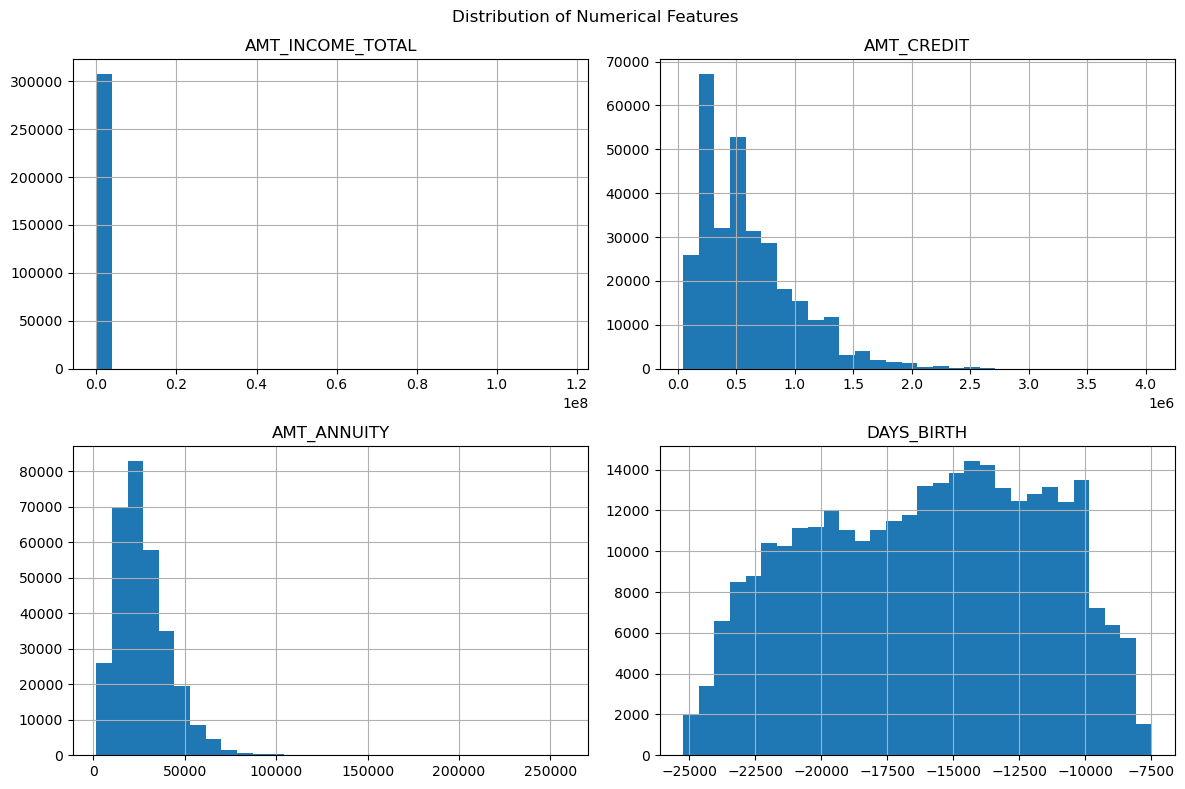

In [24]:
# Plot distributions of selected numerical features
application_train[selected_columns].hist(
    figsize=(12, 8),
    bins=30
)

plt.suptitle('Distribution of Numerical Features')
plt.tight_layout()
plt.show()

7.5 Analyze Categorical Features

In [25]:
# Select categorical columns
categorical_columns = application_train.select_dtypes(
    include=['object', 'category']
).columns

print("Number of Categorical Columns:", len(categorical_columns))
print(categorical_columns.tolist())

Number of Categorical Columns: 16
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']


7.6 Visualize Categorical Feature Distributions

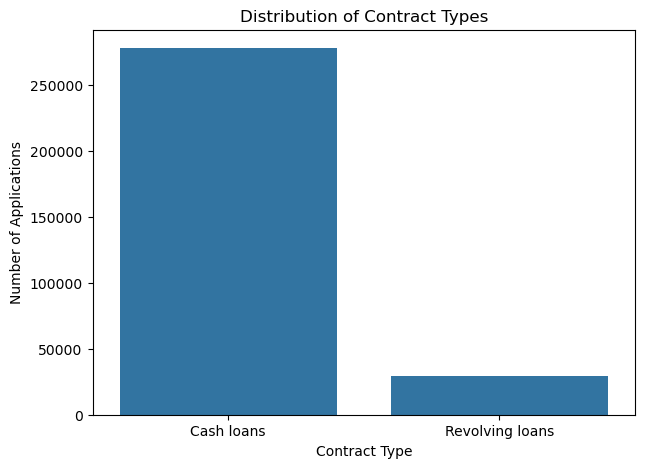

In [26]:
# Count plot for contract type
plt.figure(figsize=(7, 5))

sns.countplot(
    data=application_train,
    x='NAME_CONTRACT_TYPE'
)

plt.title('Distribution of Contract Types')
plt.xlabel('Contract Type')
plt.ylabel('Number of Applications')

plt.show()

### 7.7 Observations

1. Numerical features were examined using descriptive statistics and histograms.
2. Categorical features were identified and their distributions were visualized.
3. The analysis helps understand feature ranges, distributions, and possible skewness.
4. Specific observations will be recorded based on the generated plots and statistical results.

8. Bivariate Data Analysis

8.1 Objective

Analyze the relationship between customer features and the target variable TARGET to understand how different factors relate to loan default.

8.2 Compare Contract Type with Loan Default

In [27]:
# Compare contract type with target
pd.crosstab(
    application_train['NAME_CONTRACT_TYPE'],
    application_train['TARGET']
)

TARGET,0,1
NAME_CONTRACT_TYPE,,
Cash loans,255011,23221
Revolving loans,27675,1604


8.3 Visualize Contract Type vs Loan Default

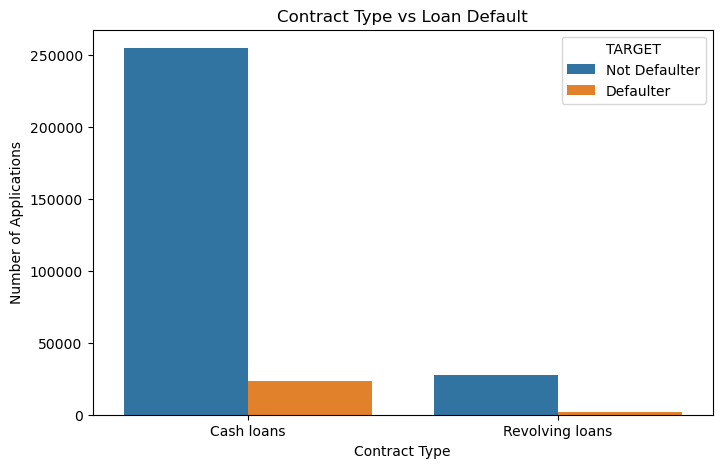

In [28]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=application_train,
    x='NAME_CONTRACT_TYPE',
    hue='TARGET'
)

plt.title('Contract Type vs Loan Default')
plt.xlabel('Contract Type')
plt.ylabel('Number of Applications')
plt.legend(title='TARGET', labels=['Not Defaulter', 'Defaulter'])

plt.show()

8.4 Compare Income with Loan Default

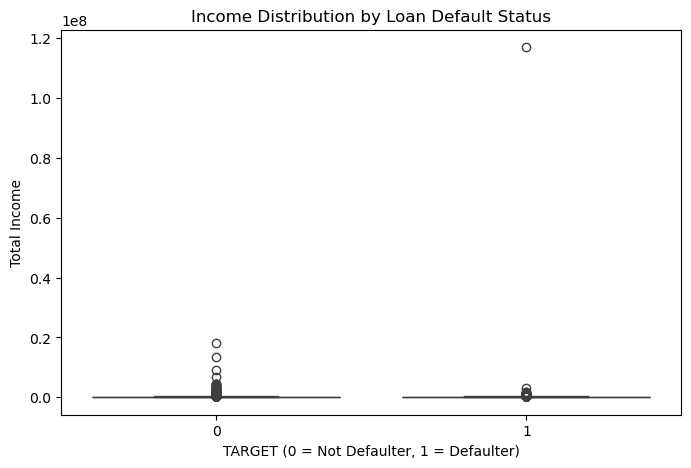

In [29]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=application_train,
    x='TARGET',
    y='AMT_INCOME_TOTAL'
)

plt.title('Income Distribution by Loan Default Status')
plt.xlabel('TARGET (0 = Not Defaulter, 1 = Defaulter)')
plt.ylabel('Total Income')

plt.show()

8.5 Compare Credit Amount with Loan Default

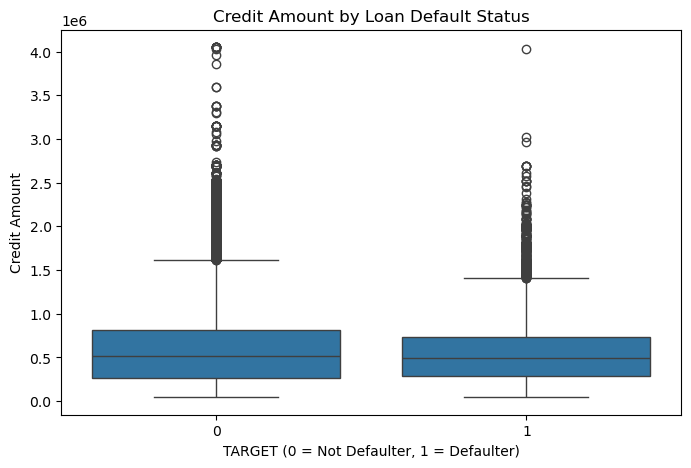

In [30]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=application_train,
    x='TARGET',
    y='AMT_CREDIT'
)

plt.title('Credit Amount by Loan Default Status')
plt.xlabel('TARGET (0 = Not Defaulter, 1 = Defaulter)')
plt.ylabel('Credit Amount')

plt.show()

8.6 Calculate Default Rates by Contract Type

In [31]:
# Calculate default rate for each contract type
default_rate = application_train.groupby(
    'NAME_CONTRACT_TYPE'
)['TARGET'].mean() * 100

print("Default Rate by Contract Type (%):")
print(default_rate)

Default Rate by Contract Type (%):
NAME_CONTRACT_TYPE
Cash loans         8.345913
Revolving loans    5.478329
Name: TARGET, dtype: float64


### 8.7 Observations

1. The relationship between contract type and loan default was examined using a cross-tabulation and count plot.
2. Income and credit amount distributions were compared across the two target classes.
3. Default rates were calculated for each contract type.
4. The results help identify potential relationships between customer features and loan default.

The final conclusions will be based on the actual results and plots generated from the dataset.

9. Outlier Analysis

9.1 Objective

Identify extreme values in important numerical features that may affect data analysis and model performance.

9.2 Analyze Outliers in Annual Income

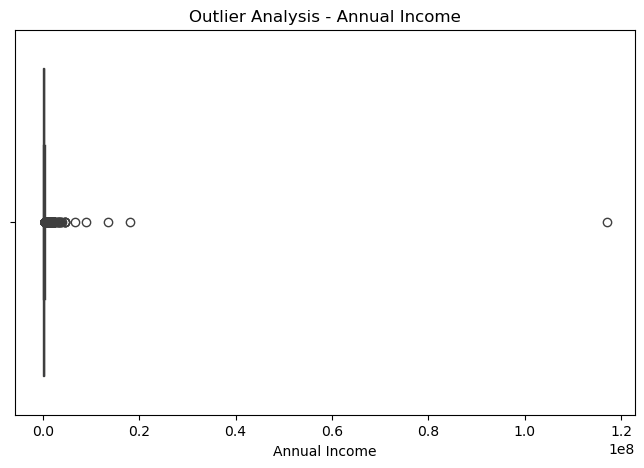

In [32]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=application_train['AMT_INCOME_TOTAL'])

plt.title('Outlier Analysis - Annual Income')
plt.xlabel('Annual Income')

plt.show()

9.3 Analyze Outliers in Credit Amount

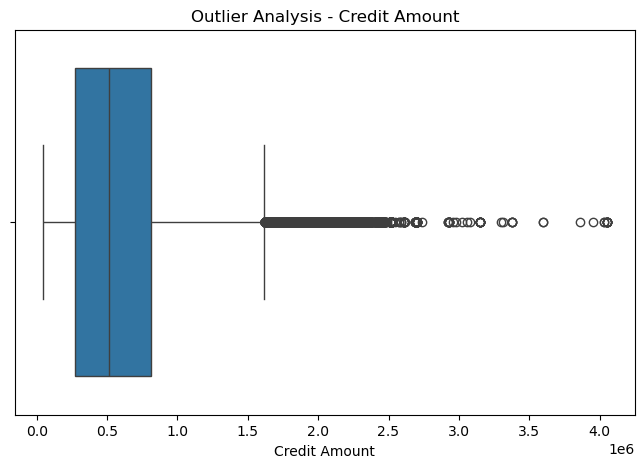

In [33]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=application_train['AMT_CREDIT'])

plt.title('Outlier Analysis - Credit Amount')
plt.xlabel('Credit Amount')

plt.show()

9.4 Analyze Outliers in Annuity Amount

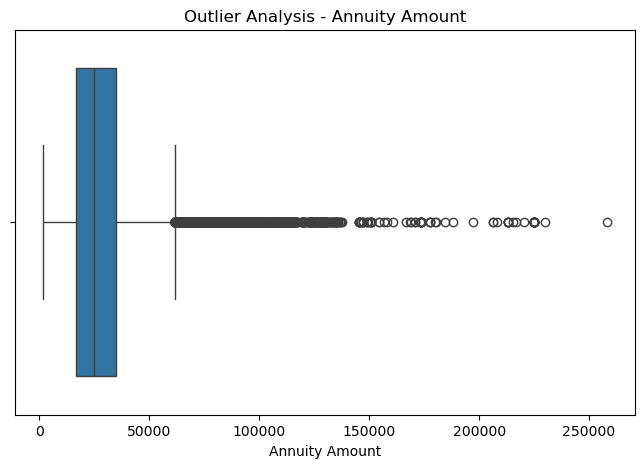

In [34]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=application_train['AMT_ANNUITY'])

plt.title('Outlier Analysis - Annuity Amount')
plt.xlabel('Annuity Amount')

plt.show()

9.5 Calculate the IQR Boundaries

In [35]:
# Calculate IQR boundaries for selected features
selected_columns = [
    'AMT_INCOME_TOTAL',
    'AMT_CREDIT',
    'AMT_ANNUITY'
]

for column in selected_columns:
    Q1 = application_train[column].quantile(0.25)
    Q3 = application_train[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = application_train[
        (application_train[column] < lower_bound) |
        (application_train[column] > upper_bound)
    ]

    print(f"\nFeature: {column}")
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of Potential Outliers:", len(outliers))


Feature: AMT_INCOME_TOTAL
Lower Bound: -22500.0
Upper Bound: 337500.0
Number of Potential Outliers: 14035

Feature: AMT_CREDIT
Lower Bound: -537975.0
Upper Bound: 1616625.0
Number of Potential Outliers: 6562

Feature: AMT_ANNUITY
Lower Bound: -10584.0
Upper Bound: 61704.0
Number of Potential Outliers: 7504


### 9.6 Observations

1. Box plots were used to visualize potential outliers in annual income, credit amount, and annuity amount.
2. The IQR method was used to calculate the lower and upper boundaries for identifying potential outliers.
3. Potential outliers will be reviewed before deciding whether any treatment is necessary.
4. Extreme values will not be removed automatically because they may represent genuine customer records.

10. Missing Value Treatment

10.1 Objective

Identify missing values in the main dataset and prepare a strategy for handling them before building the predictive models.

10.2 Create a Missing Value Summary

In [36]:
# Create a missing value summary
missing_summary = pd.DataFrame({
    'Missing_Count': application_train.isnull().sum(),
    'Missing_Percentage': (
        application_train.isnull().sum()
        / len(application_train)
    ) * 100
})

missing_summary = missing_summary[
    missing_summary['Missing_Count'] > 0
].sort_values(
    by='Missing_Percentage',
    ascending=False
)

missing_summary

,Missing_Count,Missing_Percentage
COMMONAREA_MEDI,214865,69.872297
COMMONAREA_AVG,214865,69.872297
COMMONAREA_MODE,214865,69.872297
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
NONLIVINGAPARTMENTS_MODE,213514,69.432963
...,...,...
EXT_SOURCE_2,660,0.214626
AMT_GOODS_PRICE,278,0.090403
AMT_ANNUITY,12,0.003902
CNT_FAM_MEMBERS,2,0.000650


10.3 Identify Columns with High Missing Percentages

In [37]:
# Identify columns with more than 40% missing values
high_missing_columns = missing_summary[
    missing_summary['Missing_Percentage'] > 40
]

high_missing_columns

,Missing_Count,Missing_Percentage
COMMONAREA_MEDI,214865,69.872297
COMMONAREA_AVG,214865,69.872297
COMMONAREA_MODE,214865,69.872297
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
NONLIVINGAPARTMENTS_MODE,213514,69.432963
NONLIVINGAPARTMENTS_AVG,213514,69.432963
FONDKAPREMONT_MODE,210295,68.386172
LIVINGAPARTMENTS_MODE,210199,68.354953
LIVINGAPARTMENTS_MEDI,210199,68.354953
LIVINGAPARTMENTS_AVG,210199,68.354953


10.4 Visualize Missing Values

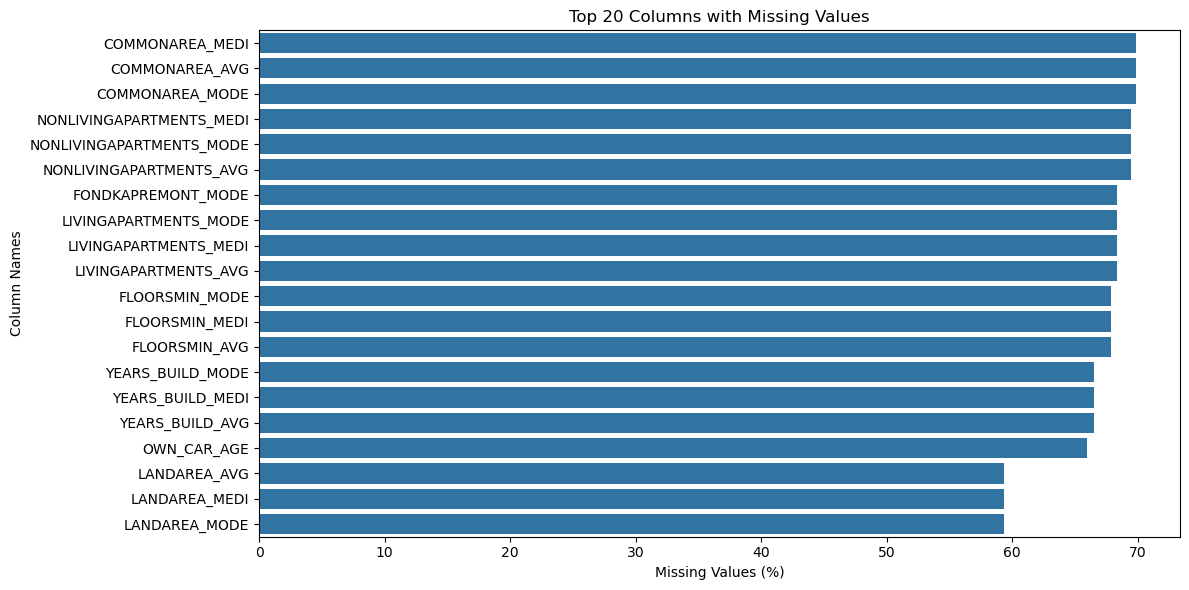

In [38]:
# Visualize the 20 columns with the most missing values
top_missing = missing_summary.head(20)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_missing['Missing_Percentage'],
    y=top_missing.index
)

plt.title('Top 20 Columns with Missing Values')
plt.xlabel('Missing Values (%)')
plt.ylabel('Column Names')

plt.tight_layout()
plt.show()

10.5 Decide the Treatment Strategy

- Numerical columns: Consider median imputation.
- Categorical columns: Consider most-frequent-value imputation or an explicit missing category.
- Columns with many missing values: Examine their meaning and usefulness before deciding whether to retain them.
- Target column: Check for missing target values separately; do not impute the target.
- Data leakage: Fit imputation methods using the training data only, then apply them to the test data.

### 10.6 Observations

1. Missing values were identified and quantified for each column.
2. The percentage of missing values was calculated to understand the extent of missing data.
3. Columns with high missing percentages were identified for further investigation.
4. Numerical and categorical features will be handled using appropriate imputation techniques during model preprocessing.
5. Imputation will be fitted on the training data to avoid data leakage.
6. No columns or records were removed at this stage.

11. Feature Engineering

11.1 Objective

Create useful features from existing customer information that may help us understand and predict loan default.

11.2 Create Customer Age in Years

In [39]:
# Convert customer age from days to years
application_train['AGE_YEARS'] = (
    -application_train['DAYS_BIRTH'] / 365.25
)

application_train[['DAYS_BIRTH', 'AGE_YEARS']].head()

,DAYS_BIRTH,AGE_YEARS
0,-9461,25.902806
1,-16765,45.900068
2,-19046,52.145106
3,-19005,52.032854
4,-19932,54.570842


11.3 Create Employment Experience in Years

In [40]:
# Check employment days
application_train['DAYS_EMPLOYED'].describe()

count    307511.000000
mean      63815.045904
std      141275.766519
min      -17912.000000
25%       -2760.000000
50%       -1213.000000
75%        -289.000000
max      365243.000000
Name: DAYS_EMPLOYED, dtype: float64

In [41]:
application_train['DAYS_EMPLOYED'].value_counts().head(10)

DAYS_EMPLOYED
 365243    55374
-200         156
-224         152
-230         151
-199         151
-212         150
-384         143
-229         143
-231         140
-215         138
Name: count, dtype: int64

11.4 Create Credit-to-Income Ratio

In [42]:
# Credit amount relative to total income
application_train['CREDIT_INCOME_RATIO'] = (
    application_train['AMT_CREDIT']
    / application_train['AMT_INCOME_TOTAL'].replace(0, np.nan)
)

application_train[['AMT_CREDIT', 'AMT_INCOME_TOTAL',
                   'CREDIT_INCOME_RATIO']].head()

,AMT_CREDIT,AMT_INCOME_TOTAL,CREDIT_INCOME_RATIO
0,406597.5,202500.0,2.007889
1,1293502.5,270000.0,4.790750
2,135000.0,67500.0,2.000000
3,312682.5,135000.0,2.316167
4,513000.0,121500.0,4.222222


11.5 Create Annuity-to-Income Ratio

In [43]:
# Annuity amount relative to total income
application_train['ANNUITY_INCOME_RATIO'] = (
    application_train['AMT_ANNUITY']
    / application_train['AMT_INCOME_TOTAL'].replace(0, np.nan)
)

application_train[['AMT_ANNUITY', 'AMT_INCOME_TOTAL',
                   'ANNUITY_INCOME_RATIO']].head()

,AMT_ANNUITY,AMT_INCOME_TOTAL,ANNUITY_INCOME_RATIO
0,24700.5,202500.0,0.121978
1,35698.5,270000.0,0.132217
2,6750.0,67500.0,0.100000
3,29686.5,135000.0,0.219900
4,21865.5,121500.0,0.179963


11.6 Verify the New Features

In [44]:
# Check the newly created features
new_features = [
    'AGE_YEARS',
    'CREDIT_INCOME_RATIO',
    'ANNUITY_INCOME_RATIO'
]

application_train[new_features].describe()

,AGE_YEARS,CREDIT_INCOME_RATIO,ANNUITY_INCOME_RATIO
count,307511.000000,307511.000000,307499.000000
mean,43.906900,3.957570,0.180930
std,11.947950,2.689728,0.094574
min,20.503765,0.004808,0.000224
25%,33.984942,2.018667,0.114782
50%,43.121150,3.265067,0.162833
75%,53.886379,5.159880,0.229067
max,69.073238,84.736842,1.875965


### 11.7 Observations

1. Customer age was converted from days into years for easier interpretation.
2. The credit-to-income ratio was created to compare credit amount with customer income.
3. The annuity-to-income ratio was created to compare annuity amount with customer income.
4. Employment information was inspected before creating an employment-duration feature.
5. The usefulness of these engineered features will be evaluated during model development.

12. Correlation Analysis

12.1 Objective

Analyze the relationships between numerical features and identify features that may be associated with loan default.

12.2 Select Numerical Features

In [45]:
# Select numerical columns
numerical_data = application_train.select_dtypes(
    include=['int64', 'float64']
)

print("Number of Numerical Features:", numerical_data.shape[1])

Number of Numerical Features: 109


12.3 Calculate Correlation with the Target

In [46]:
# Calculate correlation with TARGET
target_correlation = numerical_data.corr()['TARGET'].sort_values(
    ascending=False
)

target_correlation

TARGET                         1.000000
DAYS_BIRTH                     0.078239
REGION_RATING_CLIENT_W_CITY    0.060893
REGION_RATING_CLIENT           0.058899
DAYS_LAST_PHONE_CHANGE         0.055218
                                 ...   
DAYS_EMPLOYED                 -0.044932
AGE_YEARS                     -0.078239
EXT_SOURCE_1                  -0.155317
EXT_SOURCE_2                  -0.160472
EXT_SOURCE_3                  -0.178919
Name: TARGET, Length: 109, dtype: float64

12.4 Display the Features with the Highest Positive and Negative Correlations

In [47]:
# Display the top 10 positive correlations
print("Top 10 Positive Correlations:")
print(target_correlation.drop('TARGET').head(10))

# Display the top 10 negative correlations
print("\nTop 10 Negative Correlations:")
print(target_correlation.drop('TARGET').tail(10))

Top 10 Positive Correlations:
DAYS_BIRTH                     0.078239
REGION_RATING_CLIENT_W_CITY    0.060893
REGION_RATING_CLIENT           0.058899
DAYS_LAST_PHONE_CHANGE         0.055218
DAYS_ID_PUBLISH                0.051457
REG_CITY_NOT_WORK_CITY         0.050994
FLAG_EMP_PHONE                 0.045982
REG_CITY_NOT_LIVE_CITY         0.044395
FLAG_DOCUMENT_3                0.044346
DAYS_REGISTRATION              0.041975
Name: TARGET, dtype: float64

Top 10 Negative Correlations:
REGION_POPULATION_RELATIVE   -0.037227
AMT_GOODS_PRICE              -0.039645
FLOORSMAX_MODE               -0.043226
FLOORSMAX_MEDI               -0.043768
FLOORSMAX_AVG                -0.044003
DAYS_EMPLOYED                -0.044932
AGE_YEARS                    -0.078239
EXT_SOURCE_1                 -0.155317
EXT_SOURCE_2                 -0.160472
EXT_SOURCE_3                 -0.178919
Name: TARGET, dtype: float64


12.5 Visualize the Correlation with the Target

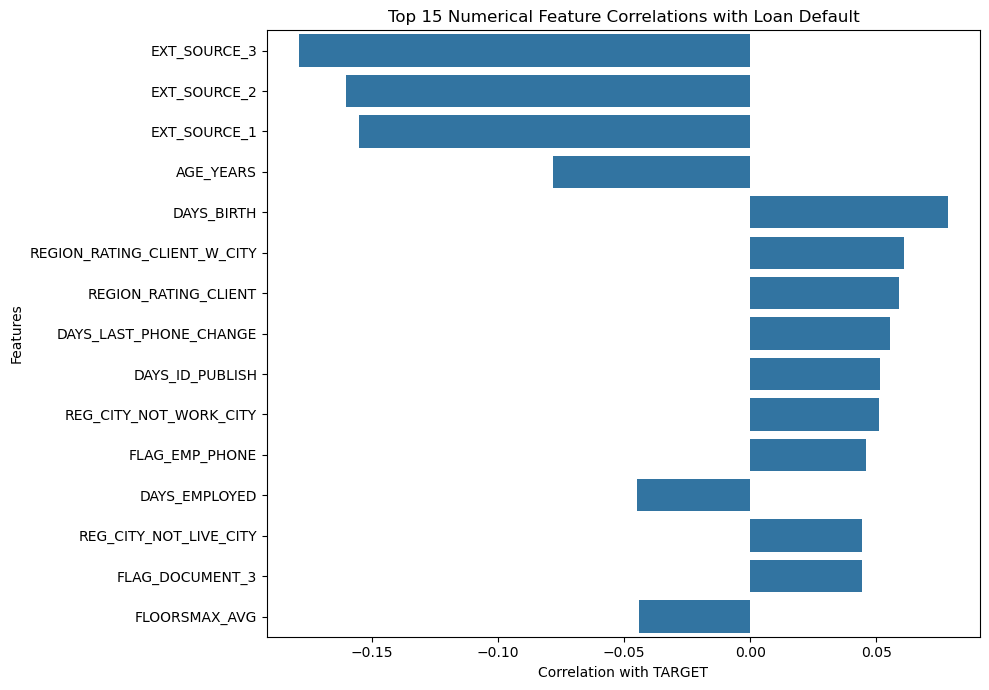

In [48]:
# Plot the 15 strongest correlations with TARGET
top_correlations = target_correlation.drop('TARGET').abs().nlargest(15).index

plt.figure(figsize=(10, 7))

sns.barplot(
    x=target_correlation.loc[top_correlations].values,
    y=top_correlations
)

plt.title('Top 15 Numerical Feature Correlations with Loan Default')
plt.xlabel('Correlation with TARGET')
plt.ylabel('Features')

plt.tight_layout()
plt.show()

12.6 Visualize Correlations Between Selected Features

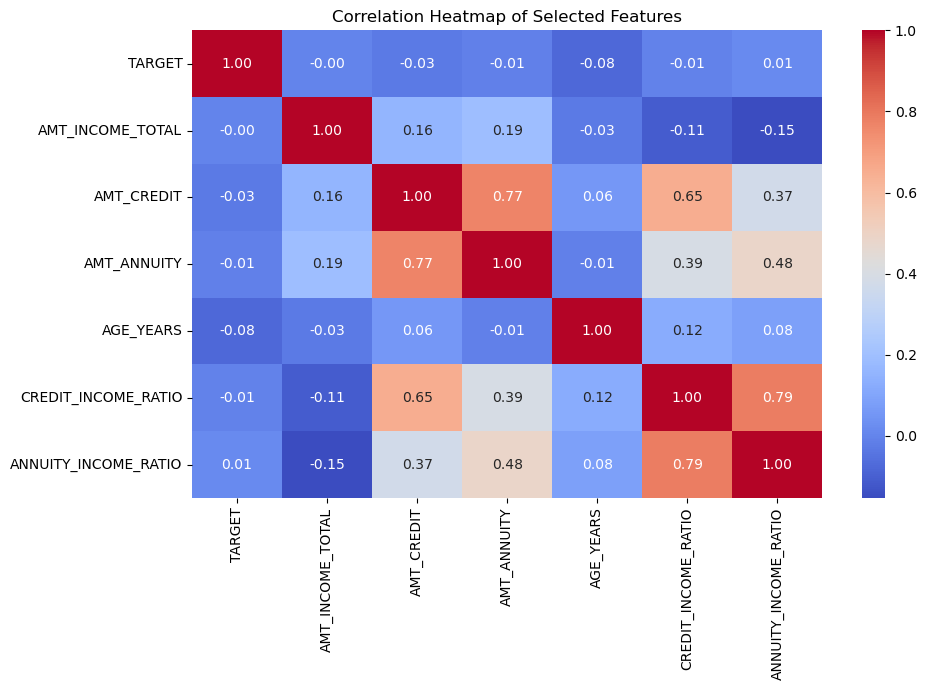

In [49]:
# Correlation heatmap for selected features
selected_features = [
    'TARGET',
    'AMT_INCOME_TOTAL',
    'AMT_CREDIT',
    'AMT_ANNUITY',
    'AGE_YEARS',
    'CREDIT_INCOME_RATIO',
    'ANNUITY_INCOME_RATIO'
]

correlation_matrix = application_train[
    selected_features
].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Selected Features')
plt.tight_layout()
plt.show()

### 12.7 Observations

1. Correlations between numerical features and the target variable were calculated.
2. Features with the strongest positive and negative correlations were identified.
3. A correlation heatmap was used to examine relationships among selected features.
4. Correlation indicates linear association and does not prove causation.
5. The relevance of the identified features will be evaluated during model development.

13. Preparing Data for Machine Learning

13.1 Objective

Prepare the main dataset for machine learning by separating the target variable from the input features and checking the dataset before model development.

13.2 Separate Features and Target

In [50]:
# Separate input features and target variable
X = application_train.drop(columns=['TARGET'])
y = application_train['TARGET']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (307511, 124)
Target Shape: (307511,)


13.3 Check the Target Distribution

In [51]:
# Check target class counts
print(y.value_counts())

# Check target class percentages
print("\nTarget Distribution (%):")
print((y.value_counts(normalize=True) * 100).round(2))

TARGET
0    282686
1     24825
Name: count, dtype: int64

Target Distribution (%):
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64


13.4 Check Feature Data Types

In [52]:
# Check numerical and categorical features
numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns

categorical_features = X.select_dtypes(
    include=['object', 'category']
).columns

print("Number of Numerical Features:", len(numerical_features))
print("Number of Categorical Features:", len(categorical_features))

Number of Numerical Features: 108
Number of Categorical Features: 16


13.5 Check Missing Values in the Input Features

In [53]:
# Count missing values in input features
print("Total Missing Values in X:", X.isnull().sum().sum())

# Display the columns with the most missing values
X.isnull().sum().sort_values(ascending=False).head(10)

Total Missing Values in X: 9152477


COMMONAREA_AVG              214865
COMMONAREA_MEDI             214865
COMMONAREA_MODE             214865
NONLIVINGAPARTMENTS_AVG     213514
NONLIVINGAPARTMENTS_MODE    213514
NONLIVINGAPARTMENTS_MEDI    213514
FONDKAPREMONT_MODE          210295
LIVINGAPARTMENTS_MODE       210199
LIVINGAPARTMENTS_AVG        210199
LIVINGAPARTMENTS_MEDI       210199
dtype: int64

### 13.6 Observations

1. The target variable was separated from the input features.
2. Numerical and categorical features were identified.
3. The target class distribution was checked before model development.
4. Missing values in the input features were examined.
5. Data preprocessing and imputation will be performed after splitting the data to prevent data leakage.

14. Train-Test Split

14.1 Objective

Split the dataset into training and testing sets so that we can train machine learning models on one portion of the data and evaluate their performance on unseen data.

14.2 Import the Required Function

In [54]:
from sklearn.model_selection import train_test_split

14.3 Split the Dataset

In [55]:
# Split features and target into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)
print("y_train Shape:", y_train.shape)
print("y_test Shape:", y_test.shape)

X_train Shape: (246008, 124)
X_test Shape: (61503, 124)
y_train Shape: (246008,)
y_test Shape: (61503,)


14.4 Verify the Target Distribution

In [56]:
# Check target percentages in each set
print("Original Target Distribution (%):")
print((y.value_counts(normalize=True) * 100).round(2))

print("\nTraining Target Distribution (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting Target Distribution (%):")
print((y_test.value_counts(normalize=True) * 100).round(2))

Original Target Distribution (%):
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64

Training Target Distribution (%):
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64

Testing Target Distribution (%):
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64


### 14.5 Observations

1. The dataset was divided into training and testing sets using an 80:20 ratio.
2. A fixed random state was used to make the split reproducible.
3. Stratified sampling was applied to preserve the target class proportions in both sets.
4. The training set will be used to fit the machine learning models, while the testing set will be used for final evaluation.

15. Data Preprocessing and Encoding

15.1 Objective

Handle missing values, encode categorical features, and scale numerical features where required so the dataset can be used by machine learning algorithms.

15.2 Import Required Libraries

In [57]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

15.3 Identify Numerical and Categorical Columns

In [58]:
# Identify numerical and categorical columns
numerical_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("Number of Numerical Features:", len(numerical_features))
print("Number of Categorical Features:", len(categorical_features))

Number of Numerical Features: 108
Number of Categorical Features: 16


15.4 Create the Numerical Preprocessing Pipeline

In [59]:
# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

15.5 Create the Categorical Preprocessing Pipeline

In [60]:
# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

15.6 Combine the Preprocessing Pipelines

In [61]:
# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


15.7 Fit and Transform the Training Data

In [62]:
# Fit preprocessing on training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same transformations to test data
X_test_processed = preprocessor.transform(X_test)

print("Processed Training Data Shape:", X_train_processed.shape)
print("Processed Testing Data Shape:", X_test_processed.shape)

Processed Training Data Shape: (246008, 248)
Processed Testing Data Shape: (61503, 248)


15.8 Verify the Processed Data

In [63]:
# Check processed data dimensions and missing values
print("Training samples:", X_train_processed.shape[0])
print("Testing samples:", X_test_processed.shape[0])
print("Number of processed features:", X_train_processed.shape[1])

Training samples: 246008
Testing samples: 61503
Number of processed features: 248


### 15.9 Observations

1. Numerical and categorical features were identified separately.
2. Missing numerical values were handled using median imputation.
3. Missing categorical values were handled using most-frequent-value imputation.
4. Categorical features were encoded using one-hot encoding.
5. Numerical features were standardized using StandardScaler.
6. The preprocessing pipeline was fitted on the training data and applied to the test data to prevent data leakage.

16. Target Class Imbalance Analysis

16.1 Objective

Check whether the dataset contains significantly more non-defaulters than defaulters. This is important because an imbalanced dataset can affect model performance.

16.2 Check Target Distribution

In [64]:
print("Target Distribution:")
print(y_train.value_counts())

print("\nTarget Percentage:")
print((y_train.value_counts(normalize=True) * 100).round(2))

Target Distribution:
TARGET
0    226148
1     19860
Name: count, dtype: int64

Target Percentage:
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64


16.3 Visualize Class Imbalance

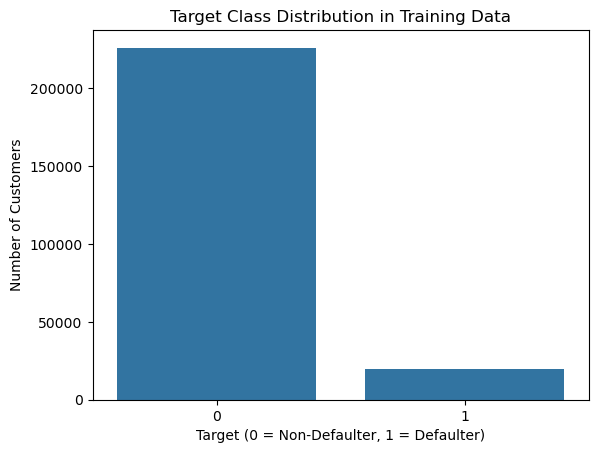

In [65]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x=y_train)

plt.title("Target Class Distribution in Training Data")
plt.xlabel("Target (0 = Non-Defaulter, 1 = Defaulter)")
plt.ylabel("Number of Customers")
plt.show()

16.4 Record Your Observation

- Which class has more records?
- What percentage of customers are defaulters?
- Is the target variable imbalanced?

16.5 Important Note
Do not apply oversampling or undersampling yet. First, understand the class distribution and evaluate the models using suitable metrics.

17. Building the Predictive Model — Logistic Regression

17.1 Objective

Build a baseline machine learning model to predict whether a customer is likely to default on a loan.

17.2 Import Required Library

In [66]:
from sklearn.linear_model import LogisticRegression

17.3 Create and Train the Model

In [67]:
logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

logistic_model.fit(X_train_processed, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


17.4 Make Predictions

In [68]:
y_pred = logistic_model.predict(X_test_processed)

print("First 20 Actual Values:")
print(y_test.iloc[:20].values)

print("\nFirst 20 Predicted Values:")
print(y_pred[:20])

First 20 Actual Values:
[0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0]

First 20 Predicted Values:
[0 0 1 1 1 1 0 0 1 0 0 1 0 0 1 0 0 0 0 0]


17.5 Record Your Observation
Add a Markdown cell and note whether the model produced predictions and whether the predicted values appear similar to the actual values.

18. Model Evaluation — Logistic Regression

18.1 Objective

Evaluate the Logistic Regression model using classification metrics. Since our goal is to identify loan defaulters, accuracy alone is not enough.

18.2 Import Evaluation Metrics

In [69]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

18.3 Calculate Evaluation Metrics

In [70]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-Score:", round(f1, 4))

Accuracy: 0.6905
Precision: 0.1617
Recall: 0.6771
F1-Score: 0.261


18.4 Display the Classification Report

In [71]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Non-Defaulter", "Defaulter"],
    zero_division=0
))

               precision    recall  f1-score   support

Non-Defaulter       0.96      0.69      0.80     56538
    Defaulter       0.16      0.68      0.26      4965

     accuracy                           0.69     61503
    macro avg       0.56      0.68      0.53     61503
 weighted avg       0.90      0.69      0.76     61503



18.5 Display the Confusion Matrix

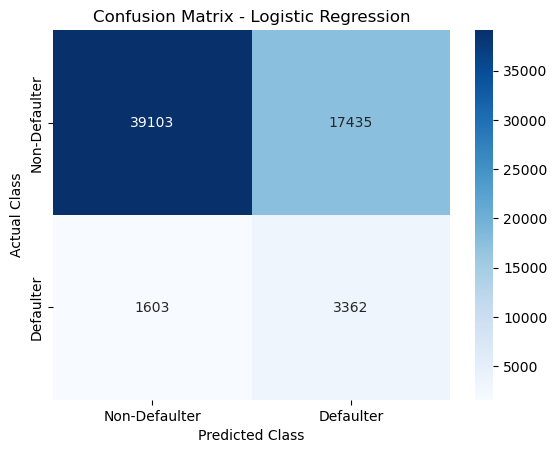

In [72]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Defaulter", "Defaulter"],
    yticklabels=["Non-Defaulter", "Defaulter"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

18.6 Understand the Results
- Accuracy: Percentage of all predictions that are correct.
- Precision: Of the customers predicted as defaulters, how many actually defaulted?
- Recall: Of all actual defaulters, how many did the model identify?
- F1-score: Balance between precision and recall.
- Confusion matrix: Shows correct and incorrect predictions for both classes.

19. Building the Predictive Model — Decision Tree

19.1 Objective

Build a Decision Tree Classifier to predict loan default. Later, we will compare its performance with Logistic Regression.

19.2 Import the Required Library

In [73]:
from sklearn.tree import DecisionTreeClassifier

19.3 Create and Train the Model

In [74]:
decision_tree_model = DecisionTreeClassifier(
    max_depth=10,
    class_weight='balanced',
    random_state=42
)

decision_tree_model.fit(X_train_processed, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,'balanced'


19.4 Make Predictions

In [75]:
y_pred_tree = decision_tree_model.predict(X_test_processed)

print("First 20 Actual Values:")
print(y_test.iloc[:20].values)

print("\nFirst 20 Predicted Values:")
print(y_pred_tree[:20])

First 20 Actual Values:
[0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0]

First 20 Predicted Values:
[1 0 1 0 1 1 0 0 1 1 1 1 0 0 0 0 0 0 0 0]


19.5 Evaluate the Decision Tree

In [76]:
print("Decision Tree Classification Report:\n")

print(classification_report(
    y_test,
    y_pred_tree,
    target_names=["Non-Defaulter", "Defaulter"],
    zero_division=0
))

Decision Tree Classification Report:

               precision    recall  f1-score   support

Non-Defaulter       0.96      0.66      0.78     56538
    Defaulter       0.14      0.65      0.24      4965

     accuracy                           0.66     61503
    macro avg       0.55      0.66      0.51     61503
 weighted avg       0.89      0.66      0.74     61503



19.6 Display the Confusion Matrix

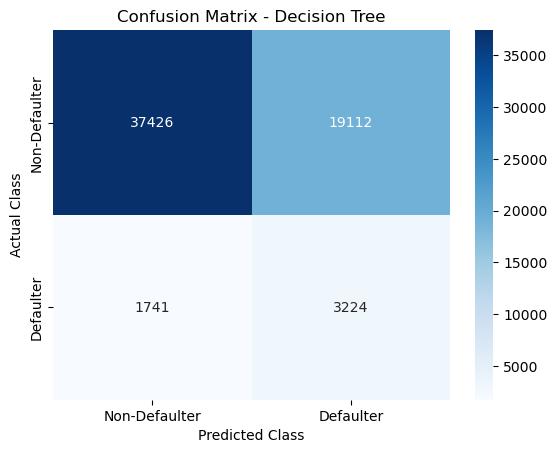

In [77]:
cm_tree = confusion_matrix(y_test, y_pred_tree)

sns.heatmap(
    cm_tree,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Defaulter", "Defaulter"],
    yticklabels=["Non-Defaulter", "Defaulter"]
)

plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

20. Building the Predictive Model — Random Forest

20.1 Objective

Build a Random Forest Classifier and evaluate its ability to identify loan defaulters. Random Forest combines multiple decision trees to make predictions.

20.2 Import the Required Library

In [78]:
from sklearn.ensemble import RandomForestClassifier

20.3 Create and Train the Model

In [79]:
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train_processed, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


20.4 Make Predictions

In [80]:
y_pred_rf = random_forest_model.predict(X_test_processed)

print("First 20 Actual Values:")
print(y_test.iloc[:20].values)

print("\nFirst 20 Predicted Values:")
print(y_pred_rf[:20])

First 20 Actual Values:
[0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0]

First 20 Predicted Values:
[0 0 1 0 1 1 0 0 1 0 0 1 0 0 1 0 0 0 0 0]


20.5 Evaluate the Random Forest

In [81]:
print("Random Forest Classification Report:\n")

print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["Non-Defaulter", "Defaulter"],
    zero_division=0
))

Random Forest Classification Report:

               precision    recall  f1-score   support

Non-Defaulter       0.95      0.73      0.83     56538
    Defaulter       0.16      0.60      0.26      4965

     accuracy                           0.72     61503
    macro avg       0.56      0.67      0.54     61503
 weighted avg       0.89      0.72      0.78     61503



20.6 Display the Confusion Matrix

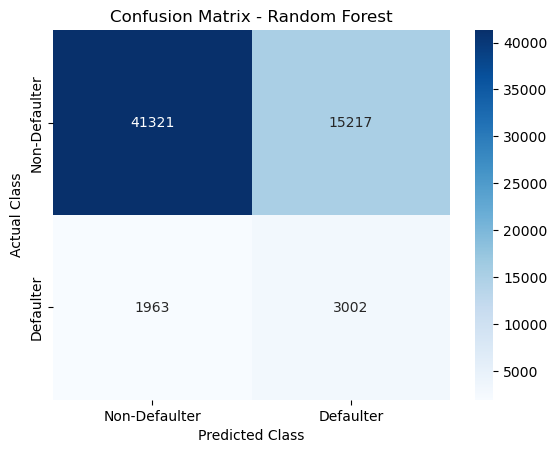

In [82]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Defaulter", "Defaulter"],
    yticklabels=["Non-Defaulter", "Defaulter"]
)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

21. Model Comparison Report

21.1 Objective

Compare the three trained models — Logistic Regression, Decision Tree, and Random Forest — using the same evaluation metrics.

21.2 Calculate Metrics for All Models

In [83]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models = {
    "Logistic Regression": y_pred,
    "Decision Tree": y_pred_tree,
    "Random Forest": y_pred_rf
}

results = []

for model_name, predictions in models.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

model_comparison = pd.DataFrame(results)

model_comparison = model_comparison.round(4)

model_comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.6905,0.1617,0.6771,0.2610
1,Decision Tree,0.6609,0.1443,0.6493,0.2362
2,Random Forest,0.7207,0.1648,0.6046,0.2590


21.3 Visualize Model Comparison

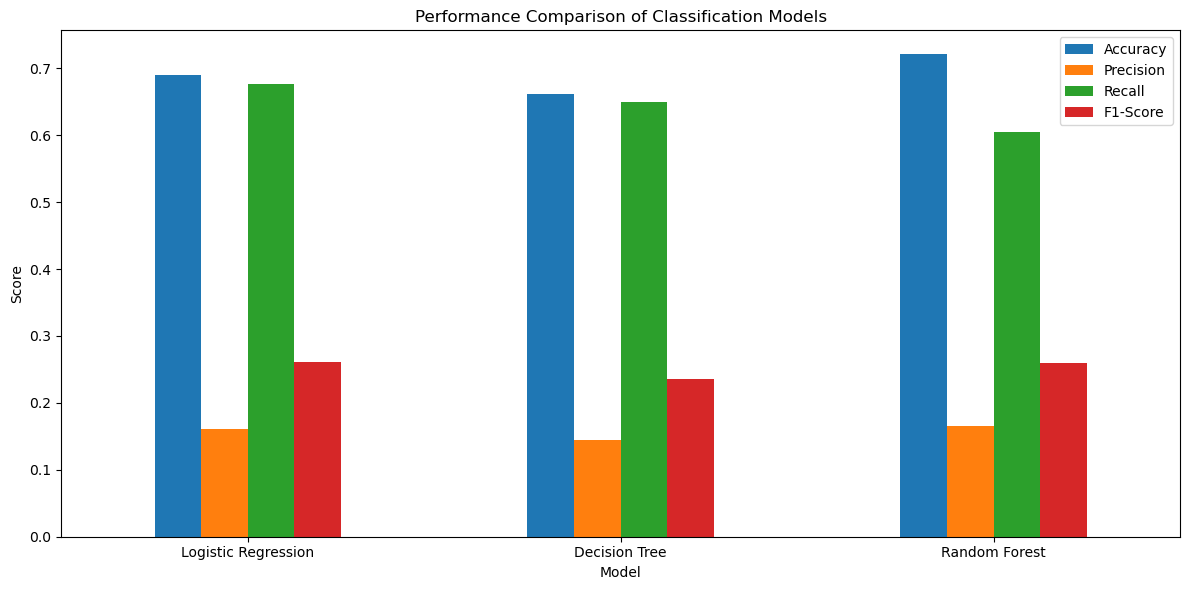

In [84]:
model_comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Performance Comparison of Classification Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend(loc="best")
plt.tight_layout()
plt.show()

21.4 Identify the Best Model

In [85]:
best_model_name = model_comparison.loc[
    model_comparison["F1-Score"].idxmax(), "Model"
]

print("Model with the Highest F1-Score:", best_model_name)

Model with the Highest F1-Score: Logistic Regression


22. Feature Importance Analysis

22.1 Objective

Identify which customer features contribute most to the Random Forest model's predictions.

22.2 Extract Feature Importance

In [86]:
feature_names = preprocessor.get_feature_names_out()

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(20)

,Feature,Importance
30,num__EXT_SOURCE_3,0.149648
29,num__EXT_SOURCE_2,0.148799
28,num__EXT_SOURCE_1,0.060422
7,num__DAYS_BIRTH,0.034909
8,num__DAYS_EMPLOYED,0.033666
105,num__AGE_YEARS,0.030472
5,num__AMT_GOODS_PRICE,0.023798
133,cat__NAME_EDUCATION_TYPE_Higher education,0.020329
78,num__DAYS_LAST_PHONE_CHANGE,0.019530
10,num__DAYS_ID_PUBLISH,0.017299


22.3 Visualize the Top 20 Features

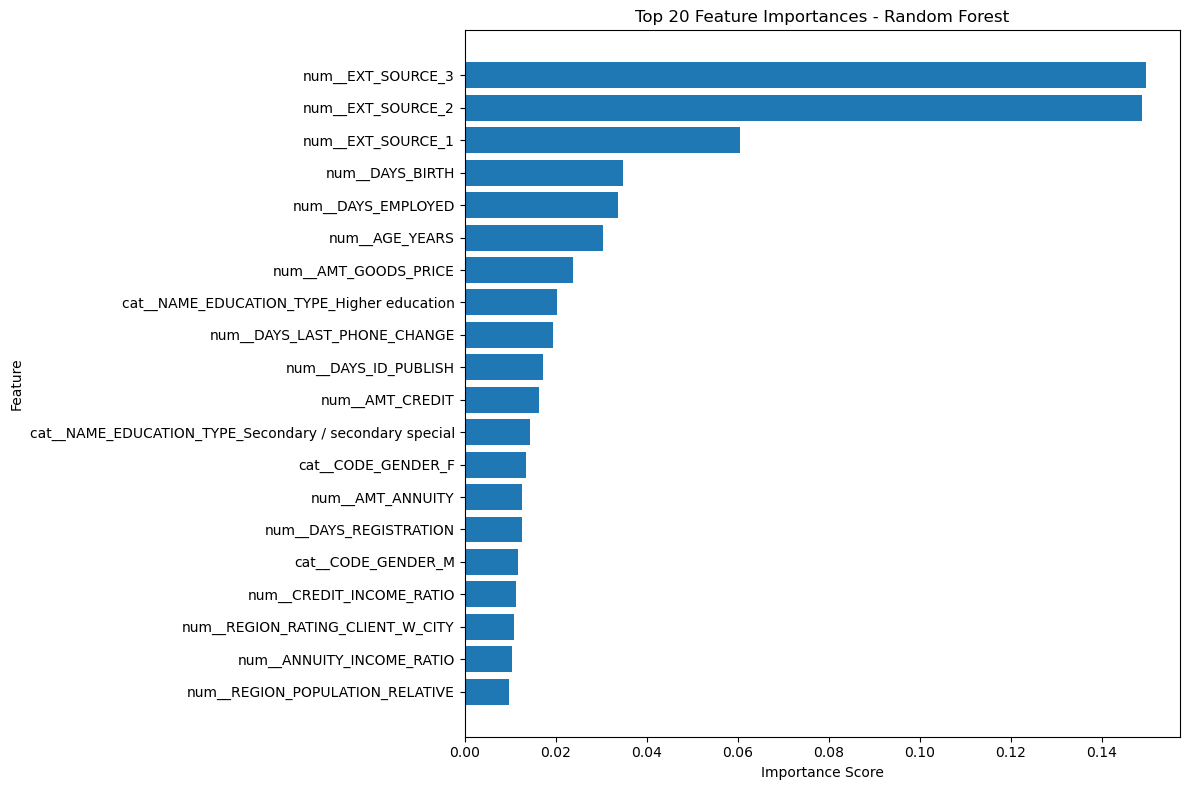

In [87]:
top_features = feature_importance.head(20).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(12, 8))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 20 Feature Importances - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

22.4 Important Note
Feature importance indicates which features the model relies on most. It does not prove that a feature causes loan default or that it should independently determine loan eligibility.

## 23. Challenges Faced and Techniques Used

### 23.1 Missing Values
The dataset contains missing values in several columns. Missing numerical values were handled using median imputation, while missing categorical values were handled using the most frequent value.

### 23.2 Class Imbalance
The target variable contains more non-defaulters than defaulters. The `class_weight='balanced'` technique was used in the classification models to help account for this imbalance.

### 23.3 Categorical Data
Machine learning models require numerical input. One-hot encoding was used to convert categorical variables into numerical features.

### 23.4 Feature Scaling
Standard scaling was applied to numerical features to put them on a comparable scale for Logistic Regression.

### 23.5 Outliers
Outliers were identified during exploratory data analysis. They were not automatically removed because extreme financial values may contain useful information.

### 23.6 Model Comparison
Logistic Regression, Decision Tree, and Random Forest were evaluated using accuracy, precision, recall, and F1-score to compare their performance.

### 23.7 Reasons for the Techniques
These techniques were selected to prepare the data for modelling, handle common data-quality issues, and evaluate the models using multiple performance measures.

24. Inspect the Supporting Datasets

24.1 Objective

In [88]:
from pathlib import Path

data_files = list(Path(".").rglob("application_train.csv"))

for file in data_files:
    print("Dataset folder:", file.parent)

Dataset folder: Downloads\Data


24.2 List the Available CSV Files

In [89]:
if data_files:
    data_folder = data_files[0].parent

    for file in sorted(data_folder.glob("*.csv")):
        print(file.name, "-", round(file.stat().st_size / (1024 ** 2), 2), "MB")
else:
    print("application_train.csv was not found.")

application_train.csv - 158.44 MB
bureau.csv - 162.14 MB
bureau_balance.csv - 358.19 MB
credit_card_balance.csv - 404.91 MB
installments_payments.csv - 689.62 MB
POS_CASH_balance.csv - 374.51 MB
previous_application.csv - 386.21 MB


25. Load and Inspect the Supporting Datasets

25.1 Load the Supporting Datasets

In [90]:
bureau = pd.read_csv(data_folder / "bureau.csv")

print("Bureau Dataset Shape:", bureau.shape)
bureau.head()

Bureau Dataset Shape: (1716428, 17)


,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_CURRENCY,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_LIMIT,AMT_CREDIT_SUM_OVERDUE,CREDIT_TYPE,DAYS_CREDIT_UPDATE,AMT_ANNUITY
0,215354,5714462,Closed,currency 1,-497,0,-153.0,-153.0,NaN,0,91323.0,0.0,NaN,0.0,Consumer credit,-131,NaN
1,215354,5714463,Active,currency 1,-208,0,1075.0,NaN,NaN,0,225000.0,171342.0,NaN,0.0,Credit card,-20,NaN
2,215354,5714464,Active,currency 1,-203,0,528.0,NaN,NaN,0,464323.5,NaN,NaN,0.0,Consumer credit,-16,NaN
3,215354,5714465,Active,currency 1,-203,0,NaN,NaN,NaN,0,90000.0,NaN,NaN,0.0,Credit card,-16,NaN
4,215354,5714466,Active,currency 1,-629,0,1197.0,NaN,77674.5,0,2700000.0,NaN,NaN,0.0,Consumer credit,-21,NaN


25.2 Inspect the Dataset Information

In [91]:
bureau.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1716428 entries, 0 to 1716427
Data columns (total 17 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   SK_ID_CURR              int64  
 1   SK_ID_BUREAU            int64  
 2   CREDIT_ACTIVE           object 
 3   CREDIT_CURRENCY         object 
 4   DAYS_CREDIT             int64  
 5   CREDIT_DAY_OVERDUE      int64  
 6   DAYS_CREDIT_ENDDATE     float64
 7   DAYS_ENDDATE_FACT       float64
 8   AMT_CREDIT_MAX_OVERDUE  float64
 9   CNT_CREDIT_PROLONG      int64  
 10  AMT_CREDIT_SUM          float64
 11  AMT_CREDIT_SUM_DEBT     float64
 12  AMT_CREDIT_SUM_LIMIT    float64
 13  AMT_CREDIT_SUM_OVERDUE  float64
 14  CREDIT_TYPE             object 
 15  DAYS_CREDIT_UPDATE      int64  
 16  AMT_ANNUITY             float64
dtypes: float64(8), int64(6), object(3)
memory usage: 222.6+ MB


25.3 Check Missing Values

In [92]:
bureau_missing = bureau.isnull().sum().sort_values(ascending=False)

bureau_missing[bureau_missing > 0].head(15)

AMT_ANNUITY               1226791
AMT_CREDIT_MAX_OVERDUE    1124488
DAYS_ENDDATE_FACT          633653
AMT_CREDIT_SUM_LIMIT       591780
AMT_CREDIT_SUM_DEBT        257669
DAYS_CREDIT_ENDDATE        105553
AMT_CREDIT_SUM                 13
dtype: int64

25.4 Understand the Dataset

In [93]:
print("Unique Customers:", bureau["SK_ID_CURR"].nunique())
print("Total Records:", len(bureau))

Unique Customers: 305811
Total Records: 1716428


26. Analyze and Aggregate Bureau Data

26.1 Objective

Summarize each customer's previous credit records into one row per customer. This allows us to merge the results into application_train without duplicating customer rows.

26.2 Check the Available Columns

In [94]:
print(bureau.columns.tolist())

['SK_ID_CURR', 'SK_ID_BUREAU', 'CREDIT_ACTIVE', 'CREDIT_CURRENCY', 'DAYS_CREDIT', 'CREDIT_DAY_OVERDUE', 'DAYS_CREDIT_ENDDATE', 'DAYS_ENDDATE_FACT', 'AMT_CREDIT_MAX_OVERDUE', 'CNT_CREDIT_PROLONG', 'AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM_LIMIT', 'AMT_CREDIT_SUM_OVERDUE', 'CREDIT_TYPE', 'DAYS_CREDIT_UPDATE', 'AMT_ANNUITY']


26.3 Analyze Credit Status

In [95]:
print("Credit Status Distribution:")
print(bureau["CREDIT_ACTIVE"].value_counts(dropna=False))

Credit Status Distribution:
CREDIT_ACTIVE
Closed      1079273
Active       630607
Sold           6527
Bad debt         21
Name: count, dtype: int64


26.4 Aggregate Records by Customer

In [96]:
bureau_agg = bureau.groupby("SK_ID_CURR").agg(
    BUREAU_RECORD_COUNT=("SK_ID_BUREAU", "count"),
    BUREAU_ACTIVE_COUNT=(
        "CREDIT_ACTIVE",
        lambda x: (x == "Active").sum()
    ),
    BUREAU_CLOSED_COUNT=(
        "CREDIT_ACTIVE",
        lambda x: (x == "Closed").sum()
    ),
    BUREAU_CREDIT_SUM=("AMT_CREDIT_SUM", "sum"),
    BUREAU_DEBT_SUM=("AMT_CREDIT_SUM_DEBT", "sum"),
    BUREAU_OVERDUE_SUM=("AMT_CREDIT_SUM_OVERDUE", "sum")
).reset_index()

bureau_agg.head()

,SK_ID_CURR,BUREAU_RECORD_COUNT,BUREAU_ACTIVE_COUNT,BUREAU_CLOSED_COUNT,BUREAU_CREDIT_SUM,BUREAU_DEBT_SUM,BUREAU_OVERDUE_SUM
0,100001,7,3,4,1453365.000,596686.5,0.0
1,100002,8,2,6,865055.565,245781.0,0.0
2,100003,4,1,3,1017400.500,0.0,0.0
3,100004,2,0,2,189037.800,0.0,0.0
4,100005,3,2,1,657126.000,568408.5,0.0


26.5 Check the Aggregated Dataset

In [97]:
print("Aggregated Bureau Shape:", bureau_agg.shape)
print("Unique Customers:", bureau_agg["SK_ID_CURR"].nunique())
print("Duplicate Customer IDs:", bureau_agg["SK_ID_CURR"].duplicated().sum())

Aggregated Bureau Shape: (305811, 7)
Unique Customers: 305811
Duplicate Customer IDs: 0


27. Analyze Bureau Balance Dataset

27.1 Load the Dataset

In [98]:
bureau_balance = pd.read_csv(data_folder / "bureau_balance.csv")

print("Dataset Shape:", bureau_balance.shape)
bureau_balance.head()

Dataset Shape: (27299925, 3)


,SK_ID_BUREAU,MONTHS_BALANCE,STATUS
0,5715448,0,C
1,5715448,-1,C
2,5715448,-2,C
3,5715448,-3,C
4,5715448,-4,C


27.2 Check Status Distribution

In [99]:
print(bureau_balance["STATUS"].value_counts(dropna=False))

STATUS
C    13646993
0     7499507
X     5810482
1      242347
5       62406
2       23419
3        8924
4        5847
Name: count, dtype: int64


27.3 Aggregate Monthly Status Records

In [100]:
bureau_balance_agg = bureau_balance.groupby("SK_ID_BUREAU").agg(
    MONTH_COUNT=("MONTHS_BALANCE", "count"),
    LATE_STATUS_COUNT=(
        "STATUS",
        lambda x: x.isin(["1", "2", "3", "4", "5"]).sum()
    )
).reset_index()

bureau_balance_agg.head()

,SK_ID_BUREAU,MONTH_COUNT,LATE_STATUS_COUNT
0,5001709,97,0
1,5001710,83,0
2,5001711,4,0
3,5001712,19,0
4,5001713,22,0


27.4 Merge with Bureau Records

In [101]:
bureau_with_balance = bureau.merge(
    bureau_balance_agg,
    on="SK_ID_BUREAU",
    how="left"
)

bureau_with_balance.head()

,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_CURRENCY,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_LIMIT,AMT_CREDIT_SUM_OVERDUE,CREDIT_TYPE,DAYS_CREDIT_UPDATE,AMT_ANNUITY,MONTH_COUNT,LATE_STATUS_COUNT
0,215354,5714462,Closed,currency 1,-497,0,-153.0,-153.0,NaN,0,91323.0,0.0,NaN,0.0,Consumer credit,-131,NaN,NaN,NaN
1,215354,5714463,Active,currency 1,-208,0,1075.0,NaN,NaN,0,225000.0,171342.0,NaN,0.0,Credit card,-20,NaN,NaN,NaN
2,215354,5714464,Active,currency 1,-203,0,528.0,NaN,NaN,0,464323.5,NaN,NaN,0.0,Consumer credit,-16,NaN,NaN,NaN
3,215354,5714465,Active,currency 1,-203,0,NaN,NaN,NaN,0,90000.0,NaN,NaN,0.0,Credit card,-16,NaN,NaN,NaN
4,215354,5714466,Active,currency 1,-629,0,1197.0,NaN,77674.5,0,2700000.0,NaN,NaN,0.0,Consumer credit,-21,NaN,NaN,NaN


28. Aggregate Bureau Data with Balance History

28.1 Objective

Combine the bureau credit information with its monthly balance history, then summarize everything into one row per customer.

28.2 Aggregate by Customer

In [102]:
bureau_combined_agg = bureau_with_balance.groupby("SK_ID_CURR").agg(
    BUREAU_TOTAL_RECORDS=("SK_ID_BUREAU", "count"),
    BUREAU_ACTIVE_RECORDS=(
        "CREDIT_ACTIVE",
        lambda x: (x == "Active").sum()
    ),
    BUREAU_TOTAL_CREDIT=("AMT_CREDIT_SUM", "sum"),
    BUREAU_TOTAL_DEBT=("AMT_CREDIT_SUM_DEBT", "sum"),
    BUREAU_TOTAL_OVERDUE=("AMT_CREDIT_SUM_OVERDUE", "sum"),
    BUREAU_AVG_MONTHS=("MONTH_COUNT", "mean"),
    BUREAU_LATE_STATUS_COUNT=("LATE_STATUS_COUNT", "sum")
).reset_index()

bureau_combined_agg.head()

,SK_ID_CURR,BUREAU_TOTAL_RECORDS,BUREAU_ACTIVE_RECORDS,BUREAU_TOTAL_CREDIT,BUREAU_TOTAL_DEBT,BUREAU_TOTAL_OVERDUE,BUREAU_AVG_MONTHS,BUREAU_LATE_STATUS_COUNT
0,100001,7,3,1453365.000,596686.5,0.0,24.571429,1.0
1,100002,8,2,865055.565,245781.0,0.0,13.750000,27.0
2,100003,4,1,1017400.500,0.0,0.0,NaN,0.0
3,100004,2,0,189037.800,0.0,0.0,NaN,0.0
4,100005,3,2,657126.000,568408.5,0.0,7.000000,0.0


28.3 Check the Result

In [103]:
print("Shape:", bureau_combined_agg.shape)
print("Unique Customers:", bureau_combined_agg["SK_ID_CURR"].nunique())
print(
    "Duplicate Customer IDs:",
    bureau_combined_agg["SK_ID_CURR"].duplicated().sum()
)

Shape: (305811, 8)
Unique Customers: 305811
Duplicate Customer IDs: 0


29. Analyze Previous Application Dataset

29.1 Load the Dataset

In [104]:
previous_application = pd.read_csv(
    data_folder / "previous_application.csv"
)

print("Dataset Shape:", previous_application.shape)
previous_application.head()

Dataset Shape: (1670214, 37)


,SK_ID_PREV,SK_ID_CURR,NAME_CONTRACT_TYPE,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,...,NAME_SELLER_INDUSTRY,CNT_PAYMENT,NAME_YIELD_GROUP,PRODUCT_COMBINATION,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL
0,2030495,271877,Consumer loans,1730.430,17145.0,17145.0,0.0,17145.0,SATURDAY,15,...,Connectivity,12.0,middle,POS mobile with interest,365243.0,-42.0,300.0,-42.0,-37.0,0.0
1,2802425,108129,Cash loans,25188.615,607500.0,679671.0,NaN,607500.0,THURSDAY,11,...,XNA,36.0,low_action,Cash X-Sell: low,365243.0,-134.0,916.0,365243.0,365243.0,1.0
2,2523466,122040,Cash loans,15060.735,112500.0,136444.5,NaN,112500.0,TUESDAY,11,...,XNA,12.0,high,Cash X-Sell: high,365243.0,-271.0,59.0,365243.0,365243.0,1.0
3,2819243,176158,Cash loans,47041.335,450000.0,470790.0,NaN,450000.0,MONDAY,7,...,XNA,12.0,middle,Cash X-Sell: middle,365243.0,-482.0,-152.0,-182.0,-177.0,1.0
4,1784265,202054,Cash loans,31924.395,337500.0,404055.0,NaN,337500.0,THURSDAY,9,...,XNA,24.0,high,Cash Street: high,NaN,NaN,NaN,NaN,NaN,NaN


29.2 Check Application Status

In [105]:
print(
    previous_application["NAME_CONTRACT_STATUS"]
    .value_counts(dropna=False)
)

NAME_CONTRACT_STATUS
Approved        1036781
Canceled         316319
Refused          290678
Unused offer      26436
Name: count, dtype: int64


29.3 Aggregate Previous Applications by Customer

In [106]:
previous_app_agg = previous_application.groupby("SK_ID_CURR").agg(
    PREV_APP_COUNT=("SK_ID_PREV", "count"),
    PREV_APPROVED_COUNT=(
        "NAME_CONTRACT_STATUS",
        lambda x: (x == "Approved").sum()
    ),
    PREV_REFUSED_COUNT=(
        "NAME_CONTRACT_STATUS",
        lambda x: (x == "Refused").sum()
    ),
    PREV_AVG_CREDIT=("AMT_CREDIT", "mean"),
    PREV_AVG_APPLICATION=("AMT_APPLICATION", "mean")
).reset_index()

previous_app_agg.head()

,SK_ID_CURR,PREV_APP_COUNT,PREV_APPROVED_COUNT,PREV_REFUSED_COUNT,PREV_AVG_CREDIT,PREV_AVG_APPLICATION
0,100001,1,1,0,23787.00,24835.50
1,100002,1,1,0,179055.00,179055.00
2,100003,3,3,0,484191.00,435436.50
3,100004,1,1,0,20106.00,24282.00
4,100005,2,1,0,20076.75,22308.75


29.4 Check the Aggregated Dataset

In [107]:
print("Shape:", previous_app_agg.shape)
print(
    "Duplicate Customer IDs:",
    previous_app_agg["SK_ID_CURR"].duplicated().sum()
)

Shape: (338857, 6)
Duplicate Customer IDs: 0


30. Analyze POS_CASH_balance Dataset

30.1 Load the Dataset

In [108]:
pos_cash = pd.read_csv(data_folder / "POS_CASH_balance.csv")

print("Dataset Shape:", pos_cash.shape)
pos_cash.head()

Dataset Shape: (10001358, 8)


,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,CNT_INSTALMENT,CNT_INSTALMENT_FUTURE,NAME_CONTRACT_STATUS,SK_DPD,SK_DPD_DEF
0,1803195,182943,-31,48.0,45.0,Active,0,0
1,1715348,367990,-33,36.0,35.0,Active,0,0
2,1784872,397406,-32,12.0,9.0,Active,0,0
3,1903291,269225,-35,48.0,42.0,Active,0,0
4,2341044,334279,-35,36.0,35.0,Active,0,0


30.2 Check Contract Status

In [109]:
print(pos_cash["NAME_CONTRACT_STATUS"].value_counts(dropna=False))

NAME_CONTRACT_STATUS
Active                   9151119
Completed                 744883
Signed                     87260
Demand                      7065
Returned to the store       5461
Approved                    4917
Amortized debt               636
Canceled                      15
XNA                            2
Name: count, dtype: int64


30.3 Aggregate POS/Cash Loan Records by Customer

In [110]:
pos_cash_agg = pos_cash.groupby("SK_ID_CURR").agg(
    POS_RECORD_COUNT=("SK_ID_PREV", "count"),
    POS_AVG_MONTHS=("MONTHS_BALANCE", "mean"),
    POS_COMPLETED_COUNT=(
        "NAME_CONTRACT_STATUS",
        lambda x: (x == "Completed").sum()
    ),
    POS_ACTIVE_COUNT=(
        "NAME_CONTRACT_STATUS",
        lambda x: (x == "Active").sum()
    ),
    POS_MAX_INSTALLMENTS=("CNT_INSTALMENT", "max"),
    POS_MAX_REMAINING_INSTALLMENTS=("CNT_INSTALMENT_FUTURE", "max")
).reset_index()

pos_cash_agg.head()

,SK_ID_CURR,POS_RECORD_COUNT,POS_AVG_MONTHS,POS_COMPLETED_COUNT,POS_ACTIVE_COUNT,POS_MAX_INSTALLMENTS,POS_MAX_REMAINING_INSTALLMENTS
0,100001,9,-72.555556,2,7,4.0,4.0
1,100002,19,-10.000000,0,19,24.0,24.0
2,100003,28,-43.785714,2,26,12.0,12.0
3,100004,4,-25.500000,1,3,4.0,4.0
4,100005,11,-20.000000,1,9,12.0,12.0


30.4 Check the Aggregated Dataset

In [111]:
print("Aggregated Shape:", pos_cash_agg.shape)
print("Unique Customers:", pos_cash_agg["SK_ID_CURR"].nunique())
print("Duplicate Customer IDs:", pos_cash_agg["SK_ID_CURR"].duplicated().sum())

Aggregated Shape: (337252, 7)
Unique Customers: 337252
Duplicate Customer IDs: 0


31. Analyze Credit Card Balance Dataset

31.1 Load the Dataset

In [112]:
credit_card = pd.read_csv(
    data_folder / "credit_card_balance.csv"
)

print("Dataset Shape:", credit_card.shape)
credit_card.head()

Dataset Shape: (3840312, 23)


,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,AMT_BALANCE,AMT_CREDIT_LIMIT_ACTUAL,AMT_DRAWINGS_ATM_CURRENT,AMT_DRAWINGS_CURRENT,AMT_DRAWINGS_OTHER_CURRENT,AMT_DRAWINGS_POS_CURRENT,AMT_INST_MIN_REGULARITY,...,AMT_RECIVABLE,AMT_TOTAL_RECEIVABLE,CNT_DRAWINGS_ATM_CURRENT,CNT_DRAWINGS_CURRENT,CNT_DRAWINGS_OTHER_CURRENT,CNT_DRAWINGS_POS_CURRENT,CNT_INSTALMENT_MATURE_CUM,NAME_CONTRACT_STATUS,SK_DPD,SK_DPD_DEF
0,2562384,378907,-6,56.970,135000,0.0,877.5,0.0,877.5,1700.325,...,0.000,0.000,0.0,1,0.0,1.0,35.0,Active,0,0
1,2582071,363914,-1,63975.555,45000,2250.0,2250.0,0.0,0.0,2250.000,...,64875.555,64875.555,1.0,1,0.0,0.0,69.0,Active,0,0
2,1740877,371185,-7,31815.225,450000,0.0,0.0,0.0,0.0,2250.000,...,31460.085,31460.085,0.0,0,0.0,0.0,30.0,Active,0,0
3,1389973,337855,-4,236572.110,225000,2250.0,2250.0,0.0,0.0,11795.760,...,233048.970,233048.970,1.0,1,0.0,0.0,10.0,Active,0,0
4,1891521,126868,-1,453919.455,450000,0.0,11547.0,0.0,11547.0,22924.890,...,453919.455,453919.455,0.0,1,0.0,1.0,101.0,Active,0,0


31.2 Check Contract Status

In [113]:
print(
    credit_card["NAME_CONTRACT_STATUS"]
    .value_counts(dropna=False)
)

NAME_CONTRACT_STATUS
Active           3698436
Completed         128918
Signed             11058
Demand              1365
Sent proposal        513
Refused               17
Approved               5
Name: count, dtype: int64


31.3 Aggregate Credit Card Records by Customer

In [114]:
credit_card_agg = credit_card.groupby("SK_ID_CURR").agg(
    CC_RECORD_COUNT=("SK_ID_PREV", "count"),
    CC_AVG_BALANCE=("AMT_BALANCE", "mean"),
    CC_MAX_BALANCE=("AMT_BALANCE", "max"),
    CC_AVG_CREDIT_LIMIT=("AMT_CREDIT_LIMIT_ACTUAL", "mean"),
    CC_AVG_DRAWINGS=("AMT_DRAWINGS_CURRENT", "mean"),
    CC_LATE_STATUS_COUNT=(
        "NAME_CONTRACT_STATUS",
        lambda x: (x == "Active").sum()
    )
).reset_index()

credit_card_agg.head()

,SK_ID_CURR,CC_RECORD_COUNT,CC_AVG_BALANCE,CC_MAX_BALANCE,CC_AVG_CREDIT_LIMIT,CC_AVG_DRAWINGS,CC_LATE_STATUS_COUNT
0,100006,6,0.000000,0.00,270000.000000,0.000000,6
1,100011,74,54482.111149,189000.00,164189.189189,2432.432432,74
2,100013,96,18159.919219,161420.22,131718.750000,5953.125000,96
3,100021,17,0.000000,0.00,675000.000000,0.000000,7
4,100023,8,0.000000,0.00,135000.000000,0.000000,8


31.4 Check the Aggregated Dataset

In [115]:
print("Aggregated Shape:", credit_card_agg.shape)
print("Unique Customers:", credit_card_agg["SK_ID_CURR"].nunique())
print(
    "Duplicate Customer IDs:",
    credit_card_agg["SK_ID_CURR"].duplicated().sum()
)

Aggregated Shape: (103558, 7)
Unique Customers: 103558
Duplicate Customer IDs: 0


CC_LATE_STATUS_COUNT counts active credit-card records, not late payments. We can rename it to CC_ACTIVE_RECORD_COUNT to make the meaning accurate:

In [116]:
credit_card_agg = credit_card_agg.rename(
    columns={"CC_LATE_STATUS_COUNT": "CC_ACTIVE_RECORD_COUNT"}
)

32. Analyze Installments Payments Dataset

32.1 Load the Dataset

In [119]:
import pandas as pd
import gc

installment_file = data_folder / "installments_payments.csv"

installment_columns = [
    "SK_ID_CURR",
    "SK_ID_PREV",
    "AMT_INSTALMENT",
    "AMT_PAYMENT"
]

installment_summary = []

for chunk in pd.read_csv(
    installment_file,
    usecols=installment_columns,
    chunksize=50000,
    dtype={
        "SK_ID_CURR": "int32",
        "SK_ID_PREV": "int32",
        "AMT_INSTALMENT": "float32",
        "AMT_PAYMENT": "float32"
    }
):
    chunk["PAYMENT_DIFFERENCE"] = (
        chunk["AMT_INSTALMENT"] - chunk["AMT_PAYMENT"]
    )

    summary = chunk.groupby("SK_ID_CURR").agg(
        RECORD_COUNT=("SK_ID_PREV", "count"),
        INSTALLMENT_SUM=("AMT_INSTALMENT", "sum"),
        PAYMENT_SUM=("AMT_PAYMENT", "sum"),
        DIFFERENCE_SUM=("PAYMENT_DIFFERENCE", "sum")
    )

    installment_summary.append(summary)

    del chunk
    gc.collect()

print("Chunks processed:", len(installment_summary))

Chunks processed: 273


In [120]:
combined = pd.concat(installment_summary)

installments_agg = combined.groupby(level=0).sum()

installments_agg["AVG_INSTALLMENT_AMOUNT"] = (
    installments_agg["INSTALLMENT_SUM"]
    / installments_agg["RECORD_COUNT"]
)

installments_agg["AVG_PAYMENT_AMOUNT"] = (
    installments_agg["PAYMENT_SUM"]
    / installments_agg["RECORD_COUNT"]
)

installments_agg = installments_agg.reset_index(
    names="SK_ID_CURR"
)

installments_agg.head()

,SK_ID_CURR,RECORD_COUNT,INSTALLMENT_SUM,PAYMENT_SUM,DIFFERENCE_SUM,AVG_INSTALLMENT_AMOUNT,AVG_PAYMENT_AMOUNT
0,100001,7,4.119593e+04,4.119593e+04,0.0,5885.132254,5885.132254
1,100002,19,2.196257e+05,2.196257e+05,0.0,11559.247533,11559.247533
2,100003,25,1.618865e+06,1.618865e+06,0.0,64754.585000,64754.585000
3,100004,3,2.128846e+04,2.128846e+04,0.0,7096.154948,7096.154948
4,100005,9,5.616184e+04,5.616184e+04,0.0,6240.204861,6240.204861


32.2 Combine Installment Payment Summaries

In [121]:
combined = pd.concat(installment_summary)

installments_agg = combined.groupby(level=0).sum()

installments_agg["AVG_INSTALLMENT_AMOUNT"] = (
    installments_agg["INSTALLMENT_SUM"]
    / installments_agg["RECORD_COUNT"]
)

installments_agg["AVG_PAYMENT_AMOUNT"] = (
    installments_agg["PAYMENT_SUM"]
    / installments_agg["RECORD_COUNT"]
)

installments_agg = installments_agg.reset_index(
    names="SK_ID_CURR"
)

installments_agg.head()

,SK_ID_CURR,RECORD_COUNT,INSTALLMENT_SUM,PAYMENT_SUM,DIFFERENCE_SUM,AVG_INSTALLMENT_AMOUNT,AVG_PAYMENT_AMOUNT
0,100001,7,4.119593e+04,4.119593e+04,0.0,5885.132254,5885.132254
1,100002,19,2.196257e+05,2.196257e+05,0.0,11559.247533,11559.247533
2,100003,25,1.618865e+06,1.618865e+06,0.0,64754.585000,64754.585000
3,100004,3,2.128846e+04,2.128846e+04,0.0,7096.154948,7096.154948
4,100005,9,5.616184e+04,5.616184e+04,0.0,6240.204861,6240.204861


32.3 Check Installment Payment Summary

In [122]:
# Check dataset dimensions
print("Shape:", installments_agg.shape)

# Check column names
print("\nColumns:")
print(installments_agg.columns.tolist())

# Check missing values
print("\nMissing values:")
print(installments_agg.isnull().sum())

# Display first five rows
installments_agg.head()

Shape: (339587, 7)

Columns:
['SK_ID_CURR', 'RECORD_COUNT', 'INSTALLMENT_SUM', 'PAYMENT_SUM', 'DIFFERENCE_SUM', 'AVG_INSTALLMENT_AMOUNT', 'AVG_PAYMENT_AMOUNT']

Missing values:
SK_ID_CURR                0
RECORD_COUNT              0
INSTALLMENT_SUM           0
PAYMENT_SUM               0
DIFFERENCE_SUM            0
AVG_INSTALLMENT_AMOUNT    0
AVG_PAYMENT_AMOUNT        0
dtype: int64


,SK_ID_CURR,RECORD_COUNT,INSTALLMENT_SUM,PAYMENT_SUM,DIFFERENCE_SUM,AVG_INSTALLMENT_AMOUNT,AVG_PAYMENT_AMOUNT
0,100001,7,4.119593e+04,4.119593e+04,0.0,5885.132254,5885.132254
1,100002,19,2.196257e+05,2.196257e+05,0.0,11559.247533,11559.247533
2,100003,25,1.618865e+06,1.618865e+06,0.0,64754.585000,64754.585000
3,100004,3,2.128846e+04,2.128846e+04,0.0,7096.154948,7096.154948
4,100005,9,5.616184e+04,5.616184e+04,0.0,6240.204861,6240.204861


32.4 Merge Installment Payment Data

In [123]:
application_train = application_train.merge(
    installments_agg,
    on="SK_ID_CURR",
    how="left"
)

print("Updated dataset shape:", application_train.shape)

application_train.head()

Updated dataset shape: (307511, 131)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,AMT_REQ_CREDIT_BUREAU_YEAR,AGE_YEARS,CREDIT_INCOME_RATIO,ANNUITY_INCOME_RATIO,RECORD_COUNT,INSTALLMENT_SUM,PAYMENT_SUM,DIFFERENCE_SUM,AVG_INSTALLMENT_AMOUNT,AVG_PAYMENT_AMOUNT
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,1.0,25.902806,2.007889,0.121978,19.0,2.196257e+05,2.196257e+05,0.000000,11559.247533,11559.247533
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0.0,45.900068,4.790750,0.132217,25.0,1.618865e+06,1.618865e+06,0.000000,64754.585000,64754.585000
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0.0,52.145106,2.000000,0.100000,3.0,2.128846e+04,2.128846e+04,0.000000,7096.154948,7096.154948
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,NaN,52.032854,2.316167,0.219900,16.0,1.007153e+06,1.007153e+06,0.000000,62947.085938,62947.085938
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0.0,54.570842,4.222222,0.179963,66.0,8.359853e+05,8.061279e+05,29857.367188,12666.444129,12214.059659


32.5 Check Missing Values After Merging

In [124]:
installment_columns = [
    "RECORD_COUNT",
    "INSTALLMENT_SUM",
    "PAYMENT_SUM",
    "DIFFERENCE_SUM",
    "AVG_INSTALLMENT_AMOUNT",
    "AVG_PAYMENT_AMOUNT"
]

print(application_train[installment_columns].isnull().sum())

RECORD_COUNT              15868
INSTALLMENT_SUM           15868
PAYMENT_SUM               15868
DIFFERENCE_SUM            15868
AVG_INSTALLMENT_AMOUNT    15868
AVG_PAYMENT_AMOUNT        15868
dtype: int64


32.6 Handle Missing Values in New Features

In [125]:
application_train[installment_columns] = (
    application_train[installment_columns].fillna(0)
)

print(application_train[installment_columns].isnull().sum())

RECORD_COUNT              0
INSTALLMENT_SUM           0
PAYMENT_SUM               0
DIFFERENCE_SUM            0
AVG_INSTALLMENT_AMOUNT    0
AVG_PAYMENT_AMOUNT        0
dtype: int64


32.7 Verify the Final Installment Features

In [126]:
application_train[
    ["SK_ID_CURR"] + installment_columns
].head()

,SK_ID_CURR,RECORD_COUNT,INSTALLMENT_SUM,PAYMENT_SUM,DIFFERENCE_SUM,AVG_INSTALLMENT_AMOUNT,AVG_PAYMENT_AMOUNT
0,100002,19.0,2.196257e+05,2.196257e+05,0.000000,11559.247533,11559.247533
1,100003,25.0,1.618865e+06,1.618865e+06,0.000000,64754.585000,64754.585000
2,100004,3.0,2.128846e+04,2.128846e+04,0.000000,7096.154948,7096.154948
3,100006,16.0,1.007153e+06,1.007153e+06,0.000000,62947.085938,62947.085938
4,100007,66.0,8.359853e+05,8.061279e+05,29857.367188,12666.444129,12214.059659


### Note: Dataset Path Change and Memory Management

During the project, we encountered `MemoryError` issues while processing large datasets. To manage the project files more effectively, we moved the datasets from the Downloads folder to `E:\HomeLoanDef\Data` and updated the dataset path in the notebook.

After the Jupyter kernel was restarted, previously created variables and intermediate DataFrames were cleared from memory. Therefore, we are restoring only the required variables and continuing the project from Section 33 instead of repeating the entire analysis and model-building process.

Note: The existing code and previous analysis remain saved in the notebook. We are continuing the remaining steps while managing memory usage carefully.

Step 1 — Set the dataset path

In [4]:
from pathlib import Path
import gc

data_folder = Path(r"E:\HomeLoanDef\Data")

print("Dataset folder exists:", data_folder.exists())
print("Main CSV exists:", (data_folder / "application_train.csv").exists())

Dataset folder exists: True
Main CSV exists: True


Step 2 — Restore the bureau summary

In [5]:
bureau = pd.read_csv(data_folder / "bureau.csv")

bureau_combined_agg = bureau.groupby("SK_ID_CURR").agg(
    BUREAU_TOTAL_RECORDS=("SK_ID_BUREAU", "count"),
    BUREAU_ACTIVE_RECORDS=(
        "CREDIT_ACTIVE", lambda x: (x == "Active").sum()
    ),
    BUREAU_TOTAL_CREDIT=("AMT_CREDIT_SUM", "sum"),
    BUREAU_TOTAL_DEBT=("AMT_CREDIT_SUM_DEBT", "sum"),
    BUREAU_TOTAL_OVERDUE=("AMT_CREDIT_SUM_OVERDUE", "sum")
).reset_index()

print("Bureau summary shape:", bureau_combined_agg.shape)

Bureau summary shape: (305811, 6)


Step 3 — Check the Bureau Summary

In [6]:
print("Bureau summary shape:", bureau_combined_agg.shape)
print("\nColumns:")
print(bureau_combined_agg.columns.tolist())

bureau_combined_agg.head()

Bureau summary shape: (305811, 6)

Columns:
['SK_ID_CURR', 'BUREAU_TOTAL_RECORDS', 'BUREAU_ACTIVE_RECORDS', 'BUREAU_TOTAL_CREDIT', 'BUREAU_TOTAL_DEBT', 'BUREAU_TOTAL_OVERDUE']


,SK_ID_CURR,BUREAU_TOTAL_RECORDS,BUREAU_ACTIVE_RECORDS,BUREAU_TOTAL_CREDIT,BUREAU_TOTAL_DEBT,BUREAU_TOTAL_OVERDUE
0,100001,7,3,1453365.000,596686.5,0.0
1,100002,8,2,865055.565,245781.0,0.0
2,100003,4,1,1017400.500,0.0,0.0
3,100004,2,0,189037.800,0.0,0.0
4,100005,3,2,657126.000,568408.5,0.0


Step 4 — Check Whether Bureau Features Are Already Merged

In [7]:
print(
    "Bureau features already merged:",
    "BUREAU_TOTAL_RECORDS" in application_train.columns
)

Bureau features already merged: False


33. Merge Supporting Dataset Summaries

33.1 Merge Bureau Features

In [8]:
application_train = application_train.merge(
    bureau_combined_agg,
    on="SK_ID_CURR",
    how="left",
    validate="one_to_one"
)

gc.collect()

print("Updated dataset shape:", application_train.shape)
print(
    "Bureau features merged:",
    "BUREAU_TOTAL_RECORDS" in application_train.columns
)

Updated dataset shape: (307511, 127)
Bureau features merged: True


33.2 Merge Previous Application Features

In [9]:
print("Previous application summary exists:", "previous_app_agg" in globals())

Previous application summary exists: False


In [10]:
previous_application = pd.read_csv(
    data_folder / "previous_application.csv",
    usecols=[
        "SK_ID_CURR",
        "SK_ID_PREV",
        "NAME_CONTRACT_STATUS",
        "AMT_CREDIT",
        "AMT_APPLICATION"
    ]
)

previous_app_agg = previous_application.groupby("SK_ID_CURR").agg(
    PREV_APP_COUNT=("SK_ID_PREV", "count"),
    PREV_APPROVED_COUNT=(
        "NAME_CONTRACT_STATUS", lambda x: (x == "Approved").sum()
    ),
    PREV_REFUSED_COUNT=(
        "NAME_CONTRACT_STATUS", lambda x: (x == "Refused").sum()
    ),
    PREV_AVG_CREDIT=("AMT_CREDIT", "mean"),
    PREV_AVG_APPLICATION=("AMT_APPLICATION", "mean")
).reset_index()

del previous_application
gc.collect()

0

In [11]:
if "PREV_APP_COUNT" not in application_train.columns:
    application_train = application_train.merge(
        previous_app_agg,
        on="SK_ID_CURR",
        how="left",
        validate="one_to_one"
    )

print("Updated shape:", application_train.shape)

Updated shape: (307511, 132)


33.3 Merge POS Cash Features

In [12]:
print("POS summary exists:", "pos_cash_agg" in globals())

POS summary exists: False


In [13]:
pos_cash = pd.read_csv(
    data_folder / "POS_CASH_balance.csv",
    usecols=[
        "SK_ID_CURR",
        "SK_ID_PREV",
        "MONTHS_BALANCE",
        "NAME_CONTRACT_STATUS",
        "CNT_INSTALMENT",
        "CNT_INSTALMENT_FUTURE"
    ]
)

pos_cash_agg = pos_cash.groupby("SK_ID_CURR").agg(
    POS_RECORD_COUNT=("SK_ID_PREV", "count"),
    POS_AVG_MONTHS=("MONTHS_BALANCE", "mean"),
    POS_COMPLETED_COUNT=(
        "NAME_CONTRACT_STATUS", lambda x: (x == "Completed").sum()
    ),
    POS_ACTIVE_COUNT=(
        "NAME_CONTRACT_STATUS", lambda x: (x == "Active").sum()
    ),
    POS_MAX_INSTALLMENTS=("CNT_INSTALMENT", "max"),
    POS_MAX_REMAINING_INSTALLMENTS=("CNT_INSTALMENT_FUTURE", "max")
).reset_index()

del pos_cash
gc.collect()

0

In [14]:
if "POS_RECORD_COUNT" not in application_train.columns:
    application_train = application_train.merge(
        pos_cash_agg,
        on="SK_ID_CURR",
        how="left",
        validate="one_to_one"
    )

print("Updated shape:", application_train.shape)

Updated shape: (307511, 138)


33.4 Merge Credit Card Features

In [15]:
print("Credit card summary exists:", "credit_card_agg" in globals())

Credit card summary exists: False


In [16]:
credit_card = pd.read_csv(
    data_folder / "credit_card_balance.csv",
    usecols=[
        "SK_ID_CURR",
        "SK_ID_PREV",
        "AMT_BALANCE",
        "AMT_CREDIT_LIMIT_ACTUAL",
        "AMT_DRAWINGS_CURRENT",
        "NAME_CONTRACT_STATUS"
    ]
)

credit_card_agg = credit_card.groupby("SK_ID_CURR").agg(
    CC_RECORD_COUNT=("SK_ID_PREV", "count"),
    CC_AVG_BALANCE=("AMT_BALANCE", "mean"),
    CC_MAX_BALANCE=("AMT_BALANCE", "max"),
    CC_AVG_CREDIT_LIMIT=("AMT_CREDIT_LIMIT_ACTUAL", "mean"),
    CC_AVG_DRAWINGS=("AMT_DRAWINGS_CURRENT", "mean"),
    CC_ACTIVE_RECORD_COUNT=(
        "NAME_CONTRACT_STATUS", lambda x: (x == "Active").sum()
    )
).reset_index()

del credit_card
gc.collect()

0

In [17]:
if "CC_RECORD_COUNT" not in application_train.columns:
    application_train = application_train.merge(
        credit_card_agg,
        on="SK_ID_CURR",
        how="left",
        validate="one_to_one"
    )

print("Updated shape:", application_train.shape)

Updated shape: (307511, 144)


33.5 Verify the Merged Dataset

In [18]:
print("Final dataset shape:", application_train.shape)

print("\nSupporting feature columns:")
print([
    col for col in application_train.columns
    if col.startswith(("BUREAU_", "PREV_", "POS_", "CC_"))
])

gc.collect()

Final dataset shape: (307511, 144)

Supporting feature columns:
['BUREAU_TOTAL_RECORDS', 'BUREAU_ACTIVE_RECORDS', 'BUREAU_TOTAL_CREDIT', 'BUREAU_TOTAL_DEBT', 'BUREAU_TOTAL_OVERDUE', 'PREV_APP_COUNT', 'PREV_APPROVED_COUNT', 'PREV_REFUSED_COUNT', 'PREV_AVG_CREDIT', 'PREV_AVG_APPLICATION', 'POS_RECORD_COUNT', 'POS_AVG_MONTHS', 'POS_COMPLETED_COUNT', 'POS_ACTIVE_COUNT', 'POS_MAX_INSTALLMENTS', 'POS_MAX_REMAINING_INSTALLMENTS', 'CC_RECORD_COUNT', 'CC_AVG_BALANCE', 'CC_MAX_BALANCE', 'CC_AVG_CREDIT_LIMIT', 'CC_AVG_DRAWINGS', 'CC_ACTIVE_RECORD_COUNT']


0

In [2]:
import pandas as pd
import os
import gc

data_folder = r"E:\HomeLoanDef\Data"

application_train = pd.read_csv(
    os.path.join(data_folder, "application_train.csv")
)

print("Dataset loaded:", application_train.shape)

Dataset loaded: (307511, 122)


Section 34 — Prepare the Final Dataset

34.1 Check Missing Values in Supporting Features

In [3]:
supporting_columns = [
    col for col in application_train.columns
    if col.startswith(("BUREAU_", "PREV_", "POS_", "CC_"))
]

print("Missing values in supporting features:")
print(application_train[supporting_columns].isnull().sum())

Missing values in supporting features:
Series([], dtype: float64)


34.2 Handle Missing Values in Supporting Features

In [5]:
from pathlib import Path

data_folder = Path(r"E:\HomeLoanDef\Data")

for filename in [
    "bureau.csv",
    "previous_application.csv",
    "POS_CASH_balance.csv",
    "credit_card_balance.csv"
]:
    print(filename, (data_folder / filename).exists())

bureau.csv True
previous_application.csv True
POS_CASH_balance.csv True
credit_card_balance.csv True


Section 34.2.1 — Restore Bureau Features

In [6]:
import gc
import pandas as pd

bureau = pd.read_csv(
    data_folder / "bureau.csv",
    usecols=[
        "SK_ID_CURR",
        "SK_ID_BUREAU",
        "CREDIT_ACTIVE",
        "AMT_CREDIT_SUM",
        "AMT_CREDIT_SUM_DEBT",
        "AMT_CREDIT_SUM_OVERDUE"
    ]
)

bureau_combined_agg = bureau.groupby("SK_ID_CURR").agg(
    BUREAU_TOTAL_RECORDS=("SK_ID_BUREAU", "count"),
    BUREAU_ACTIVE_RECORDS=(
        "CREDIT_ACTIVE", lambda x: (x == "Active").sum()
    ),
    BUREAU_TOTAL_CREDIT=("AMT_CREDIT_SUM", "sum"),
    BUREAU_TOTAL_DEBT=("AMT_CREDIT_SUM_DEBT", "sum"),
    BUREAU_TOTAL_OVERDUE=("AMT_CREDIT_SUM_OVERDUE", "sum")
).reset_index()

del bureau
gc.collect()

print("Bureau summary shape:", bureau_combined_agg.shape)

Bureau summary shape: (305811, 6)


Section 34.2.2 — Merge Bureau Features

In [7]:
application_train = application_train.merge(
    bureau_combined_agg,
    on="SK_ID_CURR",
    how="left",
    validate="one_to_one"
)

print("Updated dataset shape:", application_train.shape)

Updated dataset shape: (307511, 127)


34.3 Load and summarize previous applications

In [8]:
previous_application = pd.read_csv(
    data_folder / "previous_application.csv",
    usecols=[
        "SK_ID_CURR",
        "SK_ID_PREV",
        "NAME_CONTRACT_STATUS",
        "AMT_CREDIT",
        "AMT_APPLICATION"
    ]
)

previous_app_agg = previous_application.groupby("SK_ID_CURR").agg(
    PREV_APP_COUNT=("SK_ID_PREV", "count"),
    PREV_APPROVED_COUNT=(
        "NAME_CONTRACT_STATUS",
        lambda x: (x == "Approved").sum()
    ),
    PREV_REFUSED_COUNT=(
        "NAME_CONTRACT_STATUS",
        lambda x: (x == "Refused").sum()
    ),
    PREV_AVG_CREDIT=("AMT_CREDIT", "mean"),
    PREV_AVG_APPLICATION=("AMT_APPLICATION", "mean")
).reset_index()

del previous_application
gc.collect()

print("Previous application summary shape:", previous_app_agg.shape)

Previous application summary shape: (338857, 6)


34.3.1 Merge the features

In [9]:
if "PREV_APP_COUNT" not in application_train.columns:
    application_train = application_train.merge(
        previous_app_agg,
        on="SK_ID_CURR",
        how="left",
        validate="one_to_one"
    )

print("Updated dataset shape:", application_train.shape)

Updated dataset shape: (307511, 132)


34.4 Load and summarize POS Cash data

In [10]:
pos_cash = pd.read_csv(
    data_folder / "POS_CASH_balance.csv",
    usecols=[
        "SK_ID_CURR",
        "SK_ID_PREV",
        "MONTHS_BALANCE",
        "NAME_CONTRACT_STATUS",
        "CNT_INSTALMENT",
        "CNT_INSTALMENT_FUTURE"
    ]
)

pos_cash_agg = pos_cash.groupby("SK_ID_CURR").agg(
    POS_RECORD_COUNT=("SK_ID_PREV", "count"),
    POS_AVG_MONTHS=("MONTHS_BALANCE", "mean"),
    POS_COMPLETED_COUNT=(
        "NAME_CONTRACT_STATUS",
        lambda x: (x == "Completed").sum()
    ),
    POS_ACTIVE_COUNT=(
        "NAME_CONTRACT_STATUS",
        lambda x: (x == "Active").sum()
    ),
    POS_MAX_INSTALLMENTS=("CNT_INSTALMENT", "max"),
    POS_MAX_REMAINING_INSTALLMENTS=("CNT_INSTALMENT_FUTURE", "max")
).reset_index()

del pos_cash
gc.collect()

print("POS Cash summary shape:", pos_cash_agg.shape)

POS Cash summary shape: (337252, 7)


34.4.1 Merge the features

In [11]:
if "POS_RECORD_COUNT" not in application_train.columns:
    application_train = application_train.merge(
        pos_cash_agg,
        on="SK_ID_CURR",
        how="left",
        validate="one_to_one"
    )

print("Updated dataset shape:", application_train.shape)

Updated dataset shape: (307511, 138)


34.5 Load and summarize Credit Card data

In [12]:
credit_card = pd.read_csv(
    data_folder / "credit_card_balance.csv",
    usecols=[
        "SK_ID_CURR",
        "SK_ID_PREV",
        "AMT_BALANCE",
        "AMT_CREDIT_LIMIT_ACTUAL",
        "AMT_DRAWINGS_CURRENT",
        "NAME_CONTRACT_STATUS"
    ]
)

credit_card_agg = credit_card.groupby("SK_ID_CURR").agg(
    CC_RECORD_COUNT=("SK_ID_PREV", "count"),
    CC_AVG_BALANCE=("AMT_BALANCE", "mean"),
    CC_MAX_BALANCE=("AMT_BALANCE", "max"),
    CC_AVG_CREDIT_LIMIT=("AMT_CREDIT_LIMIT_ACTUAL", "mean"),
    CC_AVG_DRAWINGS=("AMT_DRAWINGS_CURRENT", "mean"),
    CC_ACTIVE_RECORD_COUNT=(
        "NAME_CONTRACT_STATUS",
        lambda x: (x == "Active").sum()
    )
).reset_index()

del credit_card
gc.collect()

print("Credit Card summary shape:", credit_card_agg.shape)

Credit Card summary shape: (103558, 7)


34.5.1 Merge the features

In [13]:
if "CC_RECORD_COUNT" not in application_train.columns:
    application_train = application_train.merge(
        credit_card_agg,
        on="SK_ID_CURR",
        how="left",
        validate="one_to_one"
    )

print("Updated dataset shape:", application_train.shape)

Updated dataset shape: (307511, 144)


34.6 — Restore Installment Payment Features

34.6.1 — Create installment summary

In [14]:
import gc
import pandas as pd

installment_file = data_folder / "installments_payments.csv"

installment_columns = [
    "SK_ID_CURR",
    "SK_ID_PREV",
    "AMT_INSTALMENT",
    "AMT_PAYMENT"
]

installment_summary = []

for chunk in pd.read_csv(
    installment_file,
    usecols=installment_columns,
    chunksize=10000
):
    chunk["PAYMENT_DIFFERENCE"] = (
        chunk["AMT_INSTALMENT"] - chunk["AMT_PAYMENT"]
    )

    summary = chunk.groupby("SK_ID_CURR").agg(
        RECORD_COUNT=("SK_ID_PREV", "count"),
        INSTALLMENT_SUM=("AMT_INSTALMENT", "sum"),
        PAYMENT_SUM=("AMT_PAYMENT", "sum"),
        DIFFERENCE_SUM=("PAYMENT_DIFFERENCE", "sum")
    )

    installment_summary.append(summary)

    del chunk
    gc.collect()

combined = pd.concat(installment_summary)

installments_agg = combined.groupby(level=0).sum()

installments_agg["AVG_INSTALLMENT_AMOUNT"] = (
    installments_agg["INSTALLMENT_SUM"]
    / installments_agg["RECORD_COUNT"]
)

installments_agg["AVG_PAYMENT_AMOUNT"] = (
    installments_agg["PAYMENT_SUM"]
    / installments_agg["RECORD_COUNT"]
)

installments_agg = installments_agg.reset_index(names="SK_ID_CURR")

del combined, installment_summary
gc.collect()

print("Installment summary shape:", installments_agg.shape)

Installment summary shape: (339587, 7)


34.6.2 — Merge installment summary

In [15]:
if "RECORD_COUNT" not in application_train.columns:
    application_train = application_train.merge(
        installments_agg,
        on="SK_ID_CURR",
        how="left",
        validate="one_to_one"
    )

print("Final combined dataset shape:", application_train.shape)

Final combined dataset shape: (307511, 150)


34.7 — Handle missing values in supporting features

In [16]:
supporting_prefixes = (
    "BUREAU_", "PREV_", "POS_", "CC_",
    "AVG_INSTALLMENT_", "AVG_PAYMENT_",
    "RECORD_COUNT", "INSTALLMENT_", "PAYMENT_", "DIFFERENCE_"
)

supporting_columns = [
    col for col in application_train.columns
    if col.startswith(supporting_prefixes)
]

application_train[supporting_columns] = (
    application_train[supporting_columns].fillna(0)
)

print("Supporting features:", len(supporting_columns))
print("Remaining missing values in supporting features:",
      application_train[supporting_columns].isna().sum().sum())

Supporting features: 28
Remaining missing values in supporting features: 0


34.8 — Final verification

In [17]:
print("Final dataset shape:", application_train.shape)
print("Unique customer IDs:", application_train["SK_ID_CURR"].nunique())
print("Duplicate customer IDs:", application_train["SK_ID_CURR"].duplicated().sum())
print("Target distribution:")
print(application_train["TARGET"].value_counts())

Final dataset shape: (307511, 150)
Unique customer IDs: 307511
Duplicate customer IDs: 0
Target distribution:
TARGET
0    282686
1     24825
Name: count, dtype: int64


35 — Prepare Data for Final Model

35.1 Separate features and target

In [18]:
import numpy as np
import gc

# Separate target and features
y = application_train["TARGET"]

X = application_train.drop(
    columns=["TARGET", "SK_ID_CURR"]
)

# Reduce memory usage
for col in X.select_dtypes(include=["float64"]).columns:
    X[col] = X[col].astype("float32")

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)
print("Target missing values:", y.isna().sum())

gc.collect()

Feature dataset shape: (307511, 148)
Target dataset shape: (307511,)
Target missing values: 0


0

35.2 — Split Training and Testing Data

In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (246008, 148)
Testing features: (61503, 148)
Training target: (246008,)
Testing target: (61503,)


35.3 — Prepare the Preprocessing Pipeline

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Preprocess numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocess categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Preprocessing pipeline created successfully.")

Numerical features: 132
Categorical features: 16
Preprocessing pipeline created successfully.


35.4 — Train the Final Model

In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.pipeline import Pipeline

final_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=300,
        class_weight="balanced",
        random_state=42
    ))
])

final_model.fit(X_train, y_train)

print("Final model training completed successfully.")

Final model training completed successfully.


C:\Users\ADMIN\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


35.4.1 — Fix the Convergence Warning

In [22]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Updated preprocessing pipeline successfully.")

Updated preprocessing pipeline successfully.


Retrain the model using the updated pipeline.

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

final_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

final_model.fit(X_train, y_train)

print("Updated model training completed.")

Updated model training completed.


35.5 — Evaluate the Final Model.

In [24]:
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

# Predict on test data
y_pred = final_model.predict(X_test)
y_prob = final_model.predict_proba(X_test)[:, 1]

# Display evaluation results
print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("ROC-AUC Score:", roc_auc_score(y_test, y_prob))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.70      0.81     56538
           1       0.17      0.69      0.27      4965

    accuracy                           0.70     61503
   macro avg       0.57      0.70      0.54     61503
weighted avg       0.90      0.70      0.77     61503

ROC-AUC Score: 0.7620988755096563
Confusion Matrix:
[[39590 16948]
 [ 1527  3438]]


36 — Save Final Model Results

36.1 Record the evaluation metrics

In [25]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

final_results = pd.DataFrame([{
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}])

final_results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.699608,0.168645,0.692447,0.271232,0.762099


36.2 Compare with the earlier models

In [26]:
print("Final Logistic Regression Results:")
display(final_results)

Final Logistic Regression Results:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.699608,0.168645,0.692447,0.271232,0.762099


36.3 Identify the best model

In [28]:
best_model_name = final_results.loc[
    final_results["ROC-AUC"].idxmax(),
    "Model"
]

best_roc_auc = final_results["ROC-AUC"].max()

print("Best model in the current results:", best_model_name)
print("ROC-AUC Score:", round(best_roc_auc, 4))

Best model in the current results: Logistic Regression
ROC-AUC Score: 0.7621


36.4 Visualize the final mode`l metrics

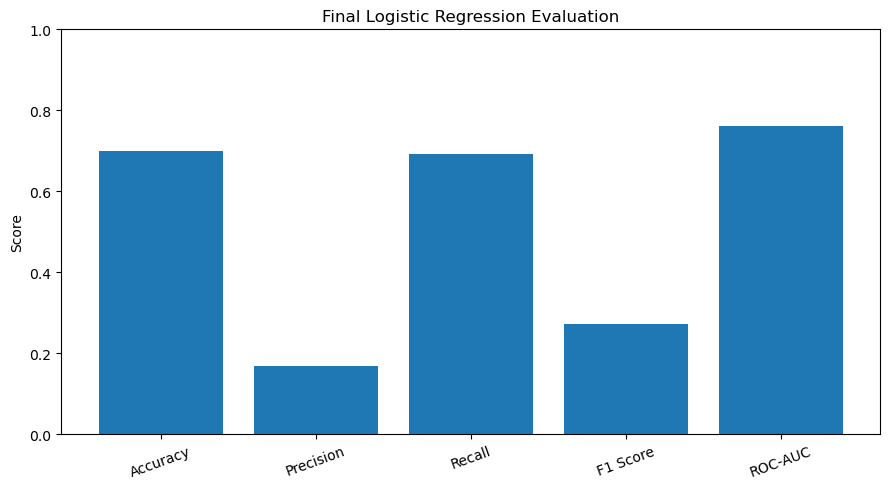

In [30]:
import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
scores = final_results.loc[0, metrics]

plt.figure(figsize=(9, 5))
plt.bar(scores.index, scores.values)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Final Logistic Regression Evaluation")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

36.5 Save the final results

In [31]:
final_results.to_csv(
    data_folder / "final_model_results.csv",
    index=False
)

print("Final model results saved successfully.")

Final model results saved successfully.


36.6 — Check Model Comparison

In [36]:
print("Logistic Regression:", "final_results" in globals())
print("Decision Tree:", "dt_model" in globals())
print("Random Forest:", "rf_model" in globals())

Logistic Regression: True
Decision Tree: False
Random Forest: False


In [37]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

dt_model = DecisionTreeClassifier(
    class_weight="balanced",
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)
dt_prob = dt_model.predict_proba(X_test)[:, 1]

print("Decision Tree ROC-AUC:", roc_auc_score(y_test, dt_prob))
print("Decision Tree F1 Score:", f1_score(y_test, dt_pred))

ValueError: could not convert string to float: 'Cash loans'

In [35]:
print(model_comparison)

NameError: name 'model_comparison' is not defined

37 — Final Project Report

37.1 Prepare the project summary

In [32]:
print("PROJECT: Home Loan Default Prediction")
print("-" * 45)

print("Dataset rows:", application_train.shape[0])
print("Total features:", X.shape[1])
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTarget Distribution:")
print(application_train["TARGET"].value_counts())

print("\nFinal Model Results:")
display(final_results)

PROJECT: Home Loan Default Prediction
---------------------------------------------
Dataset rows: 307511
Total features: 148
Training samples: 246008
Testing samples: 61503

Target Distribution:
TARGET
0    282686
1     24825
Name: count, dtype: int64

Final Model Results:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.699608,0.168645,0.692447,0.271232,0.762099


37.2 Write the project objective

Objective: To analyze customer application and historical credit data, identify factors associated with loan default, and develop a machine learning classification model to distinguish between customers who default and those who do not. The project also compares model performance and documents the challenges encountered during data processing and modeling.

37.3 Document the techniques used

- Data loading and exploratory data analysis (EDA).
- Missing-value handling and categorical feature encoding.
- Feature engineering and aggregation of supporting credit datasets.
- Train-test split using stratified sampling.
- Logistic Regression with class weighting and numerical feature scaling.
- Evaluation using precision, recall, F1-score, ROC-AUC, and a confusion matrix.
- Chunk-based processing of the large installment payment dataset to reduce memory usage.

37.4 — Document Model Evaluation Results

### Model Evaluation

The final Logistic Regression model was evaluated using a separate test dataset. The evaluation metrics include accuracy, precision, recall, F1-score, and ROC-AUC.

The confusion matrix was also used to examine correct and incorrect predictions for both default and non-default customers.

The model uses class weighting to address the imbalance between default and non-default cases. The final performance results are recorded in `final_model_results.csv`.

The model's effectiveness should be assessed using the actual evaluation scores, particularly the recall for default cases and the ROC-AUC score.

37.5 — Document Challenges and Solutions

### Challenges Faced and Solutions

1. Large dataset processing: The installment payment dataset caused memory errors when loaded entirely. It was processed in smaller chunks to reduce memory usage.

2. Missing values: Missing numerical and categorical values were handled using median and most-frequent imputation, respectively, in the preprocessing pipeline.

3. Categorical variables: One-hot encoding was used to convert categorical features into numerical representations.

4. Class imbalance: Class weighting was applied in Logistic Regression to give greater importance to the minority class.

5. Model convergence: The initial Logistic Regression model produced a convergence warning. Numerical feature scaling and an increased iteration limit were introduced to help address this issue.

37.6 — Conclusion

### Conclusion

This project analyzes customer application data and historical credit information to develop a machine learning model for loan default prediction. Supporting datasets were aggregated and combined with the main customer dataset to create additional predictive features.

Logistic Regression was trained and evaluated using a stratified training and testing split. The model's performance was measured using classification metrics and ROC-AUC.

The project demonstrates the use of data analysis, feature engineering, preprocessing, and classification techniques for loan default prediction. Further improvements may include comparing additional models, tuning hyperparameters, and validating performance on unseen data.

38 — Final Project Checks

38.1 Verify dataset and model results

In [33]:
print("HOME LOAN DEFAULT PREDICTION")
print("=" * 40)

print("Dataset shape:", application_train.shape)
print("Feature count:", X.shape[1])
print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

print("\nDuplicate customer IDs:",
      application_train["SK_ID_CURR"].duplicated().sum())

print("\nMissing target values:",
      application_train["TARGET"].isna().sum())

print("\nFinal model results:")
display(final_results)

print("\nProject verification completed.")

HOME LOAN DEFAULT PREDICTION
Dataset shape: (307511, 150)
Feature count: 148
Training rows: 246008
Testing rows: 61503

Duplicate customer IDs: 0

Missing target values: 0

Final model results:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.699608,0.168645,0.692447,0.271232,0.762099



Project verification completed.


38.2 Verify the results file

In [34]:
results_file = data_folder / "final_model_results.csv"

print("Results file exists:", results_file.exists())
print("Results file path:", results_file)

Results file exists: True
Results file path: E:\HomeLoanDef\Data\final_model_results.csv


In [ ]:
----------------------End---------------